# Compare baselines

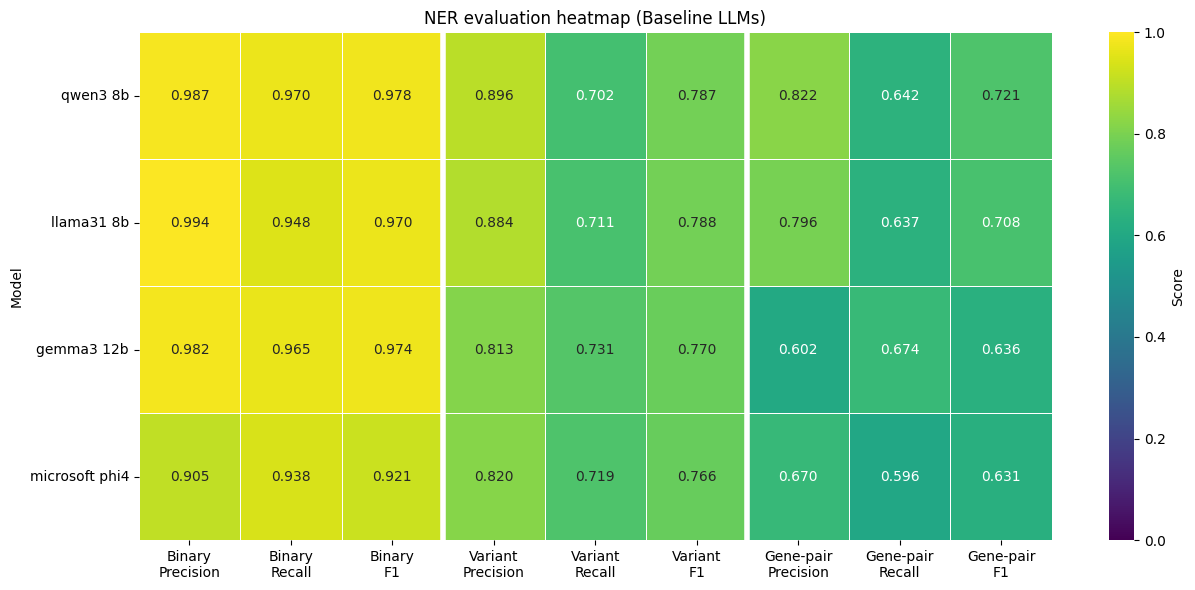

In [19]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

SUFFIX = "baseline" #_ner_qlora"
MODELS = [
    f"llama31_8b_{SUFFIX}",
    f"gemma3_12b_{SUFFIX}",
    f"microsoft_phi4_{SUFFIX}",
    f"qwen3_8b_{SUFFIX}"
    
    #f"qwen25_7b_{SUFFIX}",
    #f"qwen25_14b_{SUFFIX}",
    #f"qwen35_9b_{SUFFIX}",
    #f"gemma3_4b_{SUFFIX}",
    #f"gemma4_4b_{SUFFIX}",
    #f"mistral_7b_{SUFFIX}",
]

BASE_DIR = Path("../data/evaluation")

METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

METRIC_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORES = ["precision", "recall", "f1"]
SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

rows = []

for model in MODELS:
    with open(BASE_DIR / model / "metrics.json") as f:
        data = json.load(f)

    for metric in METRICS:
        for score in SCORES:
            rows.append(
                {
                    "model": model,
                    "task": metric,
                    "score_type": score,
                    "value": data[metric][score],
                }
            )

df = pd.DataFrame(rows)


def shorten_model_name(model_name: str) -> str:
    name = model_name.replace(f"_{SUFFIX}", "")
    name = name.replace("_ner_qlora", "")
    name = name.replace("_", " ")
    return name


df["model_label"] = df["model"].apply(shorten_model_name)

df["column"] = (
    df["task"].map(METRIC_LABELS)
    + "\n"
    + df["score_type"].map(SCORE_LABELS)
)

heatmap_df = df.pivot_table(
    index="model_label",
    columns="column",
    values="value",
)

# Force column order: Binary, Variant, Gene-pair;
# inside each group: Precision, Recall, F1.
ordered_columns = [
    f"{METRIC_LABELS[metric]}\n{SCORE_LABELS[score]}"
    for metric in METRICS
    for score in SCORES
]

heatmap_df = heatmap_df[ordered_columns]

# Optional: sort by final task F1
sort_column = "Gene-pair\nF1"
if sort_column in heatmap_df.columns:
    heatmap_df = heatmap_df.sort_values(sort_column, ascending=False)

plt.figure(figsize=(13, max(6, 0.45 * len(heatmap_df))))

ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    vmin=0,
    vmax=1,
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Score"},
)

# Separate the three sections: after Binary and after Variant.
for xpos in [3, 6]:
    ax.axvline(
        xpos,
        color="white",
        linewidth=4,
    )

plt.title("NER evaluation heatmap (Baseline LLMs)")
plt.xlabel("")
plt.ylabel("Model")

# Optional: make x labels slightly cleaner/readable
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Compare Baseline vs VariantTokenizer

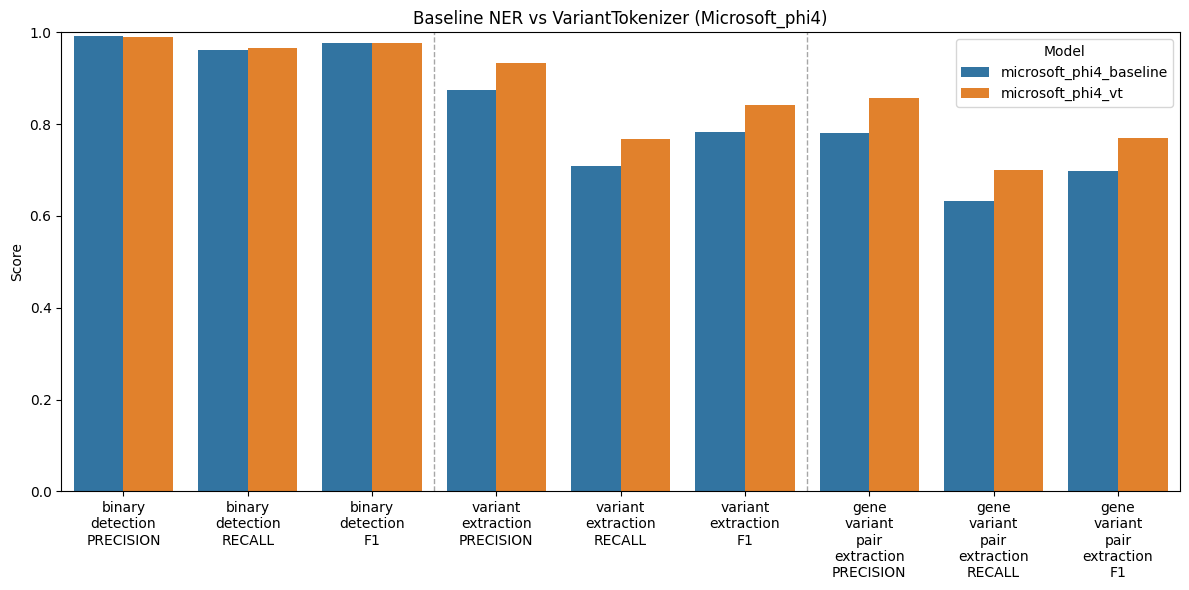

In [1]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

MODEL_FAMILY = "microsoft_phi4"
MODELS = [
    f"{MODEL_FAMILY}_baseline",
    f"{MODEL_FAMILY}_vt",
]

BASE_DIR = Path("../data/evaluation")

METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

SCORES = ["precision", "recall", "f1"]

rows = []

for model in MODELS:
    with open(BASE_DIR / model / "metrics.json") as f:
        data = json.load(f)

    for metric in METRICS:
        for score in SCORES:
            rows.append(
                {
                    "model": model,
                    "task": metric,
                    "score_type": score,
                    "value": data[metric][score],
                }
            )

df = pd.DataFrame(rows)

# Create combined category labels
df["category"] = (
    df["task"]
    .str.replace("_micro", "", regex=False)
    .str.replace("_", "\n", regex=False)
    + "\n"
    + df["score_type"].str.upper()
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=df,
    x="category",
    y="value",
    hue="model",
)

# separators between task groups
for xpos in [2.5, 5.5]:
    ax.axvline(
        xpos,
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
    )

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("")
plt.title(f"Baseline NER vs VariantTokenizer ({MODEL_FAMILY.capitalize()})")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

plt.show()

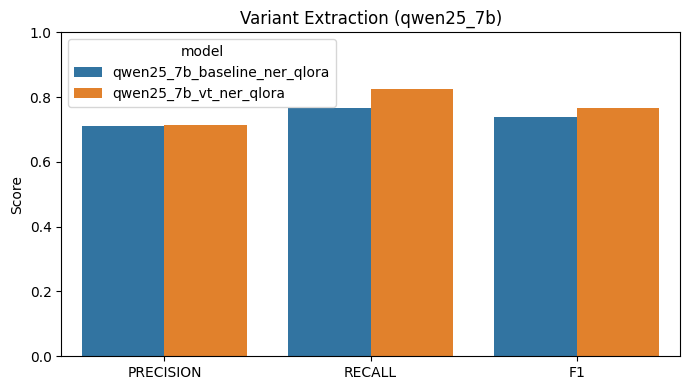

In [ ]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

MODEL_FAMILY = "microsoft_phi4"
MODELS = [
    f"{MODEL_FAMILY}_baseline",
    f"{MODEL_FAMILY}_vt",
]

BASE_DIR = Path("../data/evaluation")

METRIC = "variant_extraction_micro"
SCORES = ["precision", "recall", "f1"]

rows = []

for model in MODELS:
    with open(BASE_DIR / model / "metrics.json") as f:
        data = json.load(f)

    for score in SCORES:
        rows.append(
            {
                "model": model,
                "score_type": score.upper(),
                "value": data[METRIC][score],
            }
        )

df = pd.DataFrame(rows)

plt.figure(figsize=(7, 4))

sns.barplot(
    data=df,
    x="score_type",
    y="value",
    hue="model",
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("")
plt.title(f"Variant Extraction ({MODEL_FAMILY})")
plt.tight_layout()
plt.show()

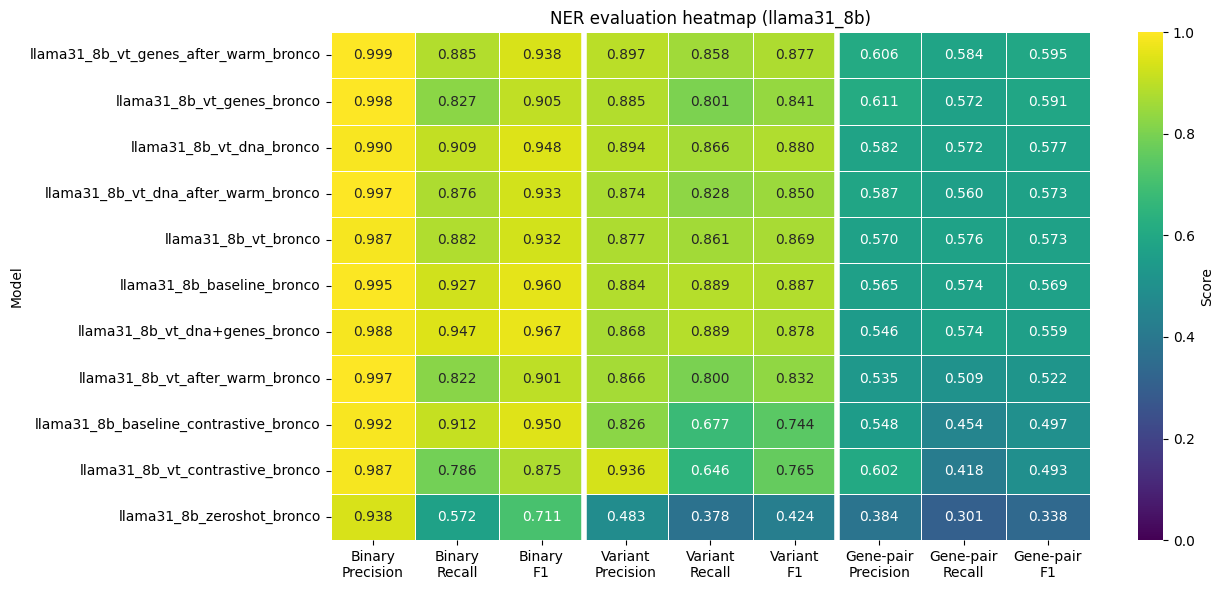

In [2]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

APPLY_ADJ = False

MODEL_FAMILY = "llama31_8b"
DATASET = "bronco"
'''MODELS = [
    f"{MODEL_FAMILY}_baseline_{DATASET}",
    #f"{MODEL_FAMILY}_vt_{DATASET}",
    #f"{MODEL_FAMILY}_baseline_contrastive_{DATASET}",
    #f"{MODEL_FAMILY}_vt_contrastive_{DATASET}",
    f"{MODEL_FAMILY}_zero_shot_{DATASET}",
]

MODELS = [f"{MODEL_FAMILY}_baseline_{d}" for d in ["hered", "varchat", "variantscape", "bronco", "tmvar"]]
MODELS = [f"{MODEL_FAMILY}_{s}_{d}" for d in ["hered", "varchat", "variantscape", "bronco", "tmvar"] for s in ["baseline", "zero_shot"]]
'''

MODELS = [
    f"{MODEL_FAMILY}_zeroshot_{DATASET}",
    f"{MODEL_FAMILY}_baseline_{DATASET}",
    f"{MODEL_FAMILY}_vt_{DATASET}",
    f"{MODEL_FAMILY}_vt_after_warm_{DATASET}",
    f"{MODEL_FAMILY}_vt_dna_{DATASET}",
    f"{MODEL_FAMILY}_vt_genes_{DATASET}",
    f"{MODEL_FAMILY}_vt_dna+genes_{DATASET}",
    f"{MODEL_FAMILY}_vt_genes_after_warm_{DATASET}",
    f"{MODEL_FAMILY}_vt_dna_after_warm_{DATASET}",
    f"{MODEL_FAMILY}_baseline_contrastive_{DATASET}",
    f"{MODEL_FAMILY}_vt_contrastive_{DATASET}",
]

BASE_DIR = Path("../evaluation")

METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"

METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

METRIC_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORES = ["precision", "recall", "f1"]
SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

rows = []

for model in MODELS:
    with open(BASE_DIR / model / METRICS_FILE) as f:
        data = json.load(f)

    for metric in METRICS:
        for score in SCORES:
            rows.append(
                {
                    "model": model,
                    "task": metric,
                    "score_type": score,
                    "value": data[metric][score],
                }
            )

df = pd.DataFrame(rows)


def shorten_model_name(name: str) -> str:
    #name = name.replace(f"_{SUFFIX}", "")
    name = name.replace("_ner_qlora", "")
    #name = name.replace("_", " ")
    #name = name.replace(f"_{DATASET}", "")
    return name


df["model_label"] = df["model"].apply(shorten_model_name)

df["column"] = (
    df["task"].map(METRIC_LABELS)
    + "\n"
    + df["score_type"].map(SCORE_LABELS)
)

heatmap_df = df.pivot_table(
    index="model_label",
    columns="column",
    values="value",
)

# Force column order: Binary, Variant, Gene-pair;
# inside each group: Precision, Recall, F1.
ordered_columns = [
    f"{METRIC_LABELS[metric]}\n{SCORE_LABELS[score]}"
    for metric in METRICS
    for score in SCORES
]

heatmap_df = heatmap_df[ordered_columns]

# Optional: sort by final task F1
sort_column = "Gene-pair\nF1"
if sort_column in heatmap_df.columns:
    heatmap_df = heatmap_df.sort_values(sort_column, ascending=False)

plt.figure(figsize=(13, max(6, 0.45 * len(heatmap_df))))

ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    vmin=0,
    vmax=1,
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Score"},
)

# Separate the three sections: after Binary and after Variant.
for xpos in [3, 6]:
    ax.axvline(
        xpos,
        color="white",
        linewidth=4,
    )

plt.title(f"NER evaluation heatmap ({MODEL_FAMILY})")
plt.xlabel("")
plt.ylabel("Model")

# Optional: make x labels slightly cleaner/readable
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

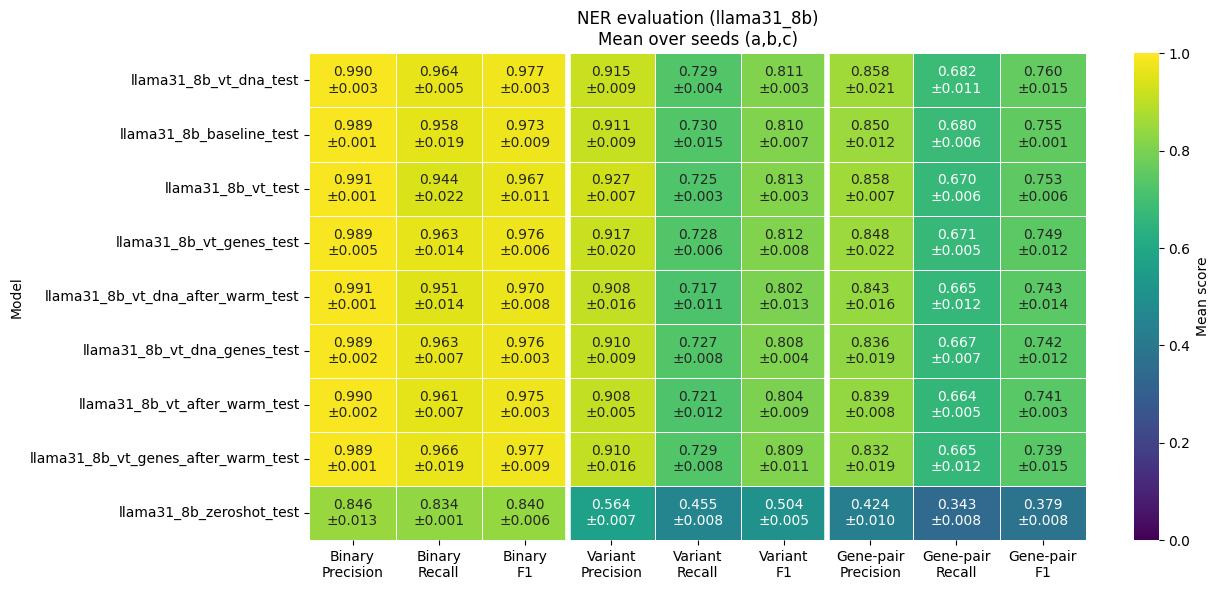

In [2]:
import json
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

APPLY_ADJ = False

MODEL_FAMILY = "llama31_8b"
DATASET = "test"
SEEDS = ["a", "b", "c"]

MODELS = [
    f"{MODEL_FAMILY}_zeroshot_{DATASET}",
    f"{MODEL_FAMILY}_baseline_{DATASET}",
    f"{MODEL_FAMILY}_vt_{DATASET}",
    f"{MODEL_FAMILY}_vt_dna_{DATASET}",
    f"{MODEL_FAMILY}_vt_genes_{DATASET}",
    f"{MODEL_FAMILY}_vt_dna_genes_{DATASET}",
    f"{MODEL_FAMILY}_vt_after_warm_{DATASET}",
    f"{MODEL_FAMILY}_vt_dna_after_warm_{DATASET}",
    f"{MODEL_FAMILY}_vt_genes_after_warm_{DATASET}",
]

BASE_DIR = Path("../evaluation_final")

METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"

METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

METRIC_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORES = ["precision", "recall", "f1"]

SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}


def shorten_model_name(name: str) -> str:
    return name.replace("_ner_qlora", "")


##############################################################################
# Load metrics from all seeds
##############################################################################

rows = []

for model in MODELS:
    for seed in SEEDS:
        metrics_path = BASE_DIR / f"{model}_{seed}" / METRICS_FILE

        with open(metrics_path) as f:
            data = json.load(f)

        for metric in METRICS:
            for score in SCORES:
                rows.append(
                    {
                        "model": model,
                        "seed": seed,
                        "task": metric,
                        "score_type": score,
                        "value": data[metric][score],
                    }
                )

df = pd.DataFrame(rows)

##############################################################################
# Aggregate across seeds
##############################################################################

summary = (
    df.groupby(["model", "task", "score_type"])["value"]
    .agg(mean="mean", min="min", max="max")
    .reset_index()
)

summary["range"] = summary["max"] - summary["min"]

summary["model_label"] = summary["model"].apply(shorten_model_name)

summary["column"] = (
    summary["task"].map(METRIC_LABELS)
    + "\n"
    + summary["score_type"].map(SCORE_LABELS)
)

##############################################################################
# Mean values (used for colors)
##############################################################################

heatmap_df = summary.pivot(
    index="model_label",
    columns="column",
    values="mean",
)

ordered_columns = [
    f"{METRIC_LABELS[m]}\n{SCORE_LABELS[s]}"
    for m in METRICS
    for s in SCORES
]

heatmap_df = heatmap_df[ordered_columns]

##############################################################################
# Annotation (mean ± half-range)
##############################################################################

annot_df = summary.copy()

annot_df["text"] = annot_df.apply(
    lambda r: f"{r['mean']:.3f}\n±{r['range']/2:.3f}",
    axis=1,
)

annot_df = annot_df.pivot(
    index="model_label",
    columns="column",
    values="text",
)

annot_df = annot_df[ordered_columns]

##############################################################################
# Sort models
##############################################################################

sort_column = "Gene-pair\nF1"

if sort_column in heatmap_df.columns:
    order = heatmap_df.sort_values(sort_column, ascending=False).index
    heatmap_df = heatmap_df.loc[order]
    annot_df = annot_df.loc[order]

##############################################################################
# Plot
##############################################################################

plt.figure(figsize=(13, max(6, 0.45 * len(heatmap_df))))

ax = sns.heatmap(
    heatmap_df,
    annot=annot_df,
    fmt="",
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Mean score"},
)

# Separate metric groups
for xpos in [3, 6]:
    ax.axvline(
        xpos,
        color="white",
        linewidth=4,
    )

plt.title(f"NER evaluation ({MODEL_FAMILY})\nMean over seeds (a,b,c)")
plt.xlabel("")
plt.ylabel("Model")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

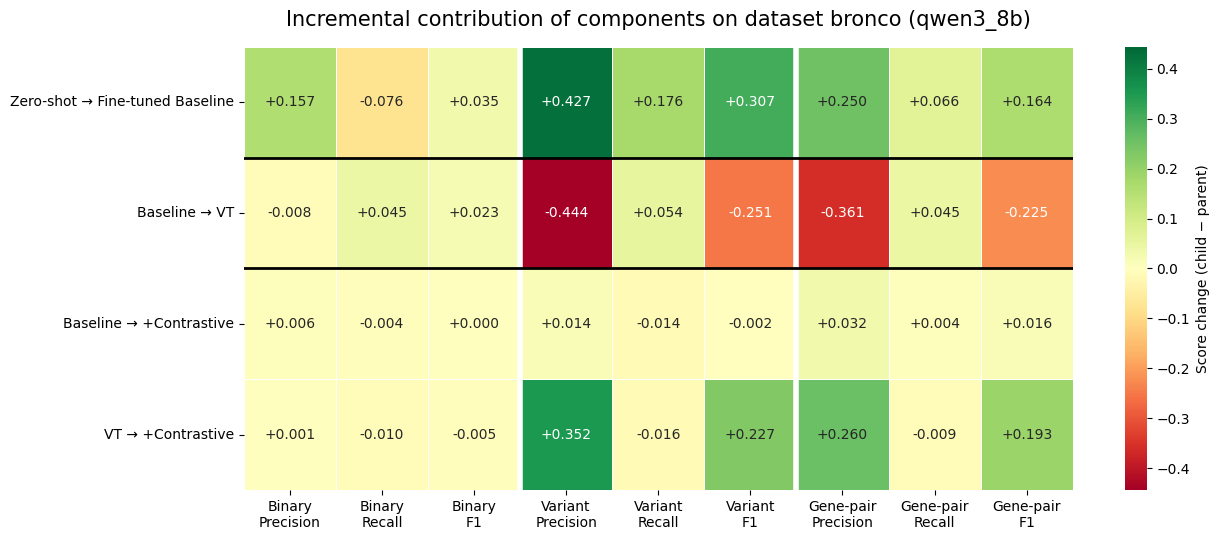

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# ============================================================
# Configuration
# ============================================================

APPLY_ADJ = False

MODEL_FAMILY = "llama31_8b"
DATASET = "test"

MODELS = {
    "zeroshot": f"{MODEL_FAMILY}_zeroshot_{DATASET}",
    "baseline": f"{MODEL_FAMILY}_baseline_{DATASET}",
    "vt": f"{MODEL_FAMILY}_vt_{DATASET}",
    "vt_after_warm": f"{MODEL_FAMILY}_vt_after_warm_{DATASET}",
    "vt_dna": f"{MODEL_FAMILY}_vt_dna_{DATASET}",
    "vt_genes": f"{MODEL_FAMILY}_vt_genes_{DATASET}",
    "vt_dna+genes": f"{MODEL_FAMILY}_vt_dna+genes_{DATASET}",
    "vt_genes_after_warm": f"{MODEL_FAMILY}_vt_genes_after_warm_{DATASET}",
    "vt_dna_after_warm": f"{MODEL_FAMILY}_vt_dna_after_warm_{DATASET}",
    "baseline_contrastive": f"{MODEL_FAMILY}_baseline_contrastive_{DATASET}",
    "vt_contrastive": f"{MODEL_FAMILY}_vt_contrastive_{DATASET}",
}

BASE_DIR = Path("../evaluation")

METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"


METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

METRIC_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORES = [
    "precision",
    "recall",
    "f1",
]

SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}


# ============================================================
# Ablation structure
#
# Delta = child - parent
#
# The order here is the order displayed in the heatmap
# ============================================================

ABLATIONS = [
    # Zero-shot
    ("Zero-shot → Fine-tuned Baseline", "baseline", "zeroshot"),

    # Baseline
    ("Baseline → VT", "vt", "baseline"),

    # VT
    ("VT → VT + DNA", "vt_dna", "vt"),
    ("VT → VT + Genes", "vt_genes", "vt"),
    ("VT → VT + DNA + Genes", "vt_dna+genes", "vt"),

    # Warmup
    ("VT → VT + Warm-up", "vt_after_warm", "vt"),
    ("VT + Genes → + Warm-up", "vt_genes_after_warm", "vt_genes"),
    ("VT + DNA → + Warm-up", "vt_dna_after_warm", "vt_dna"),

    # Contrastive learning
    ("Baseline → +Contrastive", "baseline_contrastive", "baseline"),
    ("VT → +Contrastive", "vt_contrastive", "vt"),
]


# ============================================================
# Load metrics
# ============================================================

metrics = {}

for name, model in MODELS.items():

    metric_path = BASE_DIR / model / METRICS_FILE

    if not metric_path.exists():
        raise FileNotFoundError(metric_path)

    with open(metric_path) as f:
        metrics[name] = json.load(f)


# ============================================================
# Compute deltas
# ============================================================

rows = []

for label, child, parent in ABLATIONS:

    for metric in METRICS:

        for score in SCORES:

            child_score = metrics[child][metric][score]
            parent_score = metrics[parent][metric][score]

            rows.append(
                {
                    "Comparison": label,
                    "Metric": (
                        f"{METRIC_LABELS[metric]}\n"
                        f"{SCORE_LABELS[score]}"
                    ),
                    "Delta": child_score - parent_score,
                }
            )


df = pd.DataFrame(rows)


# ============================================================
# Preserve experimental order
# ============================================================

comparison_order = [
    label
    for label, _, _ in ABLATIONS
]

df["Comparison"] = pd.Categorical(
    df["Comparison"],
    categories=comparison_order,
    ordered=True,
)


# ============================================================
# Create heatmap matrix
# ============================================================

heatmap_df = df.pivot(
    index="Comparison",
    columns="Metric",
    values="Delta",
)

# Explicitly restore row order
heatmap_df = heatmap_df.reindex(comparison_order)


# Explicit metric order
ordered_columns = [
    f"{METRIC_LABELS[metric]}\n{SCORE_LABELS[score]}"
    for metric in METRICS
    for score in SCORES
]

heatmap_df = heatmap_df[ordered_columns]


# ============================================================
# Plot
# ============================================================

max_abs = heatmap_df.abs().values.max()

plt.figure(figsize=(13, 5.5))

ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt="+.3f",
    cmap="RdYlGn",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Score change (child − parent)"
    },
)


# ============================================================
# Visual grouping
# ============================================================

# Separate:
# Binary | Variant | Gene-pair

for xpos in [3, 6]:
    ax.axvline(
        xpos,
        color="white",
        linewidth=4,
    )


# Separate:
#
# Baseline
# ----------
# VT
# ----------
# Specialized models

for ypos in [1, 2, 5, 8]:
    ax.axhline(
        ypos,
        color="black",
        linewidth=2,
    )


# ============================================================
# Formatting
# ============================================================

plt.title(
    f"Incremental contribution of components on dataset {DATASET} ({MODEL_FAMILY})",
    fontsize=15,
    pad=15,
)

plt.xlabel("")
plt.ylabel("")

plt.xticks(
    rotation=0,
    fontsize=10,
)

plt.yticks(
    rotation=0,
    fontsize=10,
)

plt.tight_layout()

plt.show()

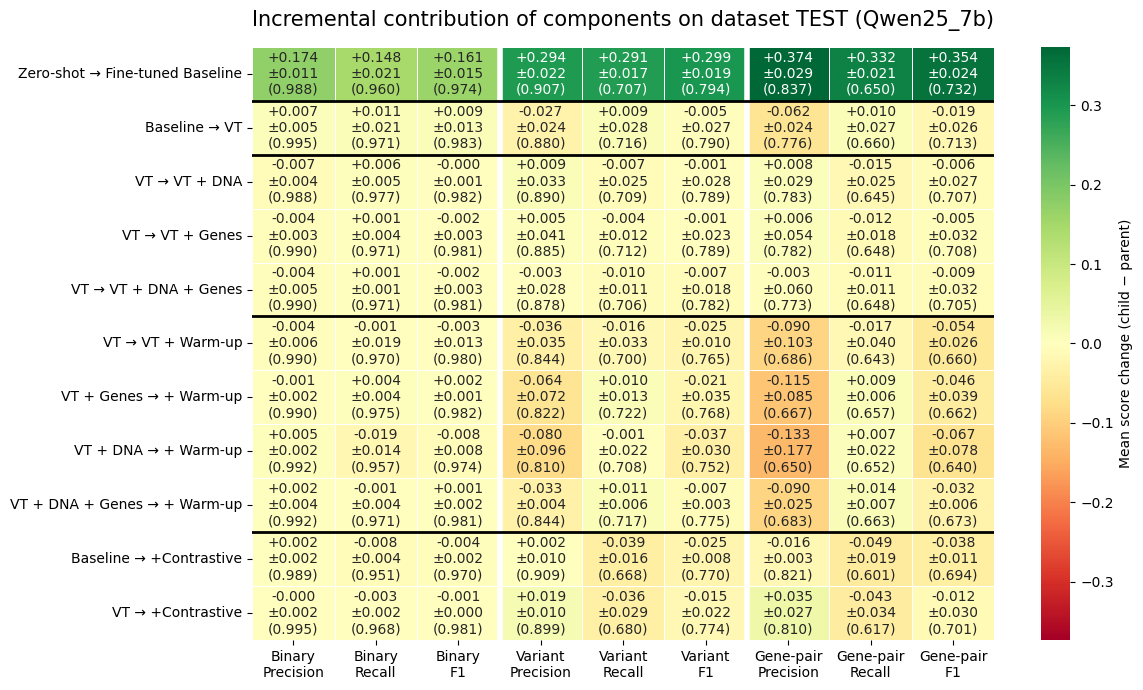

In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# ============================================================
# Configuration
# ============================================================

APPLY_ADJ = False

MODEL_FAMILY = "qwen25_7b"
BASELINE = "previous"
DATASET = "test"

MODELS = {
    "zeroshot": f"{MODEL_FAMILY}_zeroshot_{DATASET}",
    "baseline": f"{MODEL_FAMILY}_baseline_{DATASET}",
    "vt": f"{MODEL_FAMILY}_vt_{DATASET}",
    "vt_dna": f"{MODEL_FAMILY}_vt_dna_{DATASET}",
    "vt_genes": f"{MODEL_FAMILY}_vt_genes_{DATASET}",
    "vt_dna_genes": f"{MODEL_FAMILY}_vt_dna_genes_{DATASET}",
    "vt_after_warm": f"{MODEL_FAMILY}_vt_after_warm_{DATASET}",
    "vt_dna_after_warm": f"{MODEL_FAMILY}_vt_dna_after_warm_{DATASET}",
    "vt_genes_after_warm": f"{MODEL_FAMILY}_vt_genes_after_warm_{DATASET}",
    "vt_dna_genes_after_warm": f"{MODEL_FAMILY}_vt_dna_genes_after_warm_{DATASET}",
    "baseline_contrastive": f"{MODEL_FAMILY}_baseline_contrastive_{DATASET}",
    "vt_contrastive": f"{MODEL_FAMILY}_vt_contrastive_{DATASET}",
}

BASE_DIR = Path("../evaluation_final")

METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"


METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

METRIC_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORES = [
    "precision",
    "recall",
    "f1",
]

SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}


# ============================================================
# Ablation structure
#
# Delta = child - parent
#
# The order here is the order displayed in the heatmap
# ============================================================

if BASELINE == "previous":
    ABLATIONS = [
        # Zero-shot
        ("Zero-shot → Fine-tuned Baseline", "baseline", "zeroshot"),

        # Baseline
        ("Baseline → VT", "vt", "baseline"),

        # VT
        ("VT → VT + DNA", "vt_dna", "vt"),
        ("VT → VT + Genes", "vt_genes", "vt"),
        ("VT → VT + DNA + Genes", "vt_dna_genes", "vt"),

        # Warmup
        ("VT → VT + Warm-up", "vt_after_warm", "vt"),
        ("VT + Genes → + Warm-up", "vt_genes_after_warm", "vt_genes"),
        ("VT + DNA → + Warm-up", "vt_dna_after_warm", "vt_dna"),
        ("VT + DNA + Genes → + Warm-up", "vt_dna_genes_after_warm", "vt_dna_genes"),

        # Contrastive learning
        ("Baseline → +Contrastive", "baseline_contrastive", "baseline"),
        ("VT → +Contrastive", "vt_contrastive", "vt"),
    ]
elif BASELINE == "baseline":
    ABLATIONS = [
        # Zero-shot
        ("Zero-shot → Fine-tuned Baseline", "baseline", "zeroshot"),

        # Baseline
        ("Baseline → VT", "vt", "baseline"),

        # VT
        ("Baseline → VT + DNA", "vt_dna", "baseline"),
        ("Baseline → VT + Genes", "vt_genes", "baseline"),
        ("Baseline → VT + DNA + Genes", "vt_dna_genes", "baseline"),

        # Warmup
        ("Baseline → VT + Warm-up", "vt_after_warm", "baseline"),
        ("Baseline → VT + Genes + Warm-up", "vt_genes_after_warm", "baseline"),
        ("Baseline → VT + DNA + Warm-up", "vt_dna_after_warm", "baseline"),
        ("Baseline → VT + DNA + Genes + Warm-up + Warm-up", "vt_dna_genes_after_warm", "baseline"),

        # Contrastive learning
        ("Baseline → Baseline + Contrastive", "baseline_contrastive", "baseline"),
        ("Baseline → VT + Contrastive", "vt_contrastive", "baseline"),
    ]


# ============================================================
# Load metrics
# ============================================================

SEEDS = ["a", "b", "c"]

rows = []

for label, child, parent in ABLATIONS:

    for metric in METRICS:
        for score in SCORES:

            deltas = []
            avg_parent_perf = []
            avg_child_perf = []

            for seed in SEEDS:

                child_path = (
                    BASE_DIR /
                    f"{MODELS[child]}_{seed}" /
                    METRICS_FILE
                )

                parent_path = (
                    BASE_DIR /
                    f"{MODELS[parent]}_{seed}" /
                    METRICS_FILE
                )

                with open(child_path) as f:
                    child_metrics = json.load(f)

                with open(parent_path) as f:
                    parent_metrics = json.load(f)

                delta = (
                    child_metrics[metric][score]
                    - parent_metrics[metric][score]
                )

                deltas.append(delta)
                avg_parent_perf.append(parent_metrics[metric][score])
                avg_child_perf.append(child_metrics[metric][score])

            rows.append(
                {
                    "Comparison": label,
                    "Metric": (
                        f"{METRIC_LABELS[metric]}\n"
                        f"{SCORE_LABELS[score]}"
                    ),
                    "Mean": sum(deltas) / len(deltas),
                    "Std": pd.Series(deltas).std(ddof=1),
                    "Min": min(deltas),
                    "Max": max(deltas),
                    "ParentPerf": sum(avg_parent_perf) / len(avg_parent_perf),
                    "ChildPerf": sum(avg_child_perf) / len(avg_child_perf),
                }
            )

df = pd.DataFrame(rows)


# ============================================================
# Preserve experimental order
# ============================================================

comparison_order = [label for label, _, _ in ABLATIONS]

df["Comparison"] = pd.Categorical(
    df["Comparison"],
    categories=comparison_order,
    ordered=True,
)

# ============================================================
# Create heatmap matrices
# ============================================================

ordered_columns = [
    f"{METRIC_LABELS[metric]}\n{SCORE_LABELS[score]}"
    for metric in METRICS
    for score in SCORES
]

# Mean delta (used for colors)
heatmap_df = (
    df.pivot(
        index="Comparison",
        columns="Metric",
        values="Mean",
    )
    .reindex(comparison_order)
)

heatmap_df = heatmap_df[ordered_columns]

# Annotation (parent mean, delta, std)
annot_df = df.copy()

annot_df["Annotation"] = annot_df.apply(
    lambda r: (
        f"{r['Mean']:+.3f}\n"
        f"±{r['Std']:.3f}\n"
        f"({r['ChildPerf']:.3f})"
    ),
    axis=1,
)

annot_df = (
    annot_df.pivot(
        index="Comparison",
        columns="Metric",
        values="Annotation",
    )
    .reindex(comparison_order)
)

annot_df = annot_df[ordered_columns]

# ============================================================
# Plot
# ============================================================

max_abs = heatmap_df.abs().to_numpy().max()

plt.figure(figsize=(12, 7))

ax = sns.heatmap(
    heatmap_df,
    annot=annot_df,
    fmt="",
    cmap="RdYlGn",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Mean score change (child − parent)" if BASELINE != "baseline" else "Mean score change (strategy − baseline)"
    },
)

# ============================================================
# Visual grouping
# ============================================================

# Separate:
# Binary | Variant | Gene-pair
for xpos in [3, 6]:
    ax.axvline(
        xpos,
        color="white",
        linewidth=4,
    )

# Separate:
# Baseline
# ----------
# VT
# ----------
# Specialized models
for ypos in [1, 2, 5, 9]:
    ax.axhline(
        ypos,
        color="black",
        linewidth=2,
    )

# ============================================================
# Formatting
# ============================================================

plt.title(
    f"Performance comparison to Baseline on dataset {DATASET.upper()} ({MODEL_FAMILY.capitalize()})" if BASELINE == "baseline" else
    f"Incremental contribution of components on dataset {DATASET.upper()} ({MODEL_FAMILY.capitalize()})",
    fontsize=15,
    pad=15,
)

plt.xlabel("")
plt.ylabel("")

plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.savefig(f'./figures/{MODEL_FAMILY}_{BASELINE}_{DATASET}.png', dpi=600, bbox_inches='tight')
plt.show()

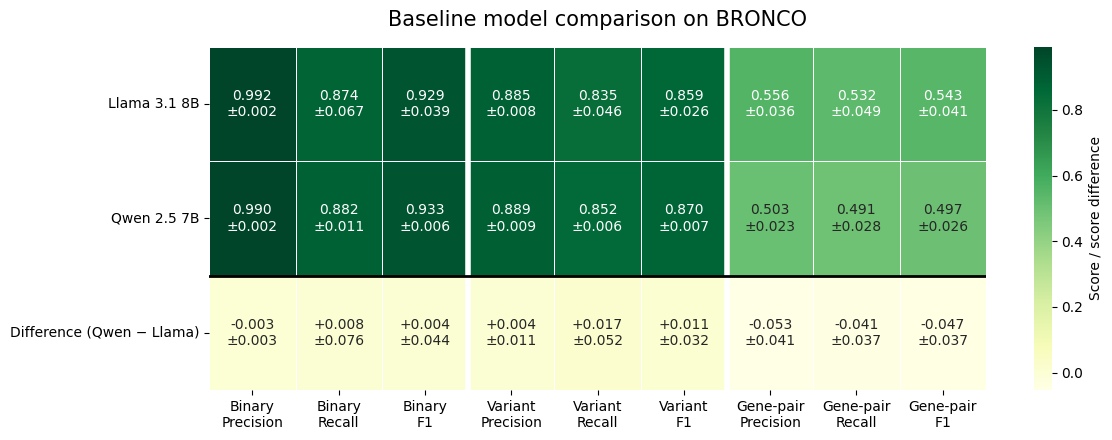

                    Model               Metric      Mean      Std       Min       Max
             Llama 3.1 8B    Binary\nPrecision  0.992323 0.002109  0.990840  0.994737
             Llama 3.1 8B       Binary\nRecall  0.874426 0.067472  0.812265  0.946183
             Llama 3.1 8B           Binary\nF1  0.928786 0.038813  0.892710  0.969852
             Llama 3.1 8B   Variant\nPrecision  0.884612 0.008422  0.876475  0.893293
             Llama 3.1 8B      Variant\nRecall  0.835464 0.045887  0.791193  0.882812
             Llama 3.1 8B          Variant\nF1  0.858953 0.026007  0.831654  0.883440
             Llama 3.1 8B Gene-pair\nPrecision  0.555680 0.036108  0.521434  0.593398
             Llama 3.1 8B    Gene-pair\nRecall  0.532197 0.049422  0.475142  0.561790
             Llama 3.1 8B        Gene-pair\nF1  0.543428 0.041410  0.497213  0.577162
              Qwen 2.5 7B    Binary\nPrecision  0.989714 0.001542  0.988717  0.991489
              Qwen 2.5 7B       Binary\nRecall  0.8823

In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# ============================================================
# Configuration
# ============================================================

APPLY_ADJ = False

# Select dataset here
DATASET = "bronco"

BASE_DIR = Path("../evaluation_final")

METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"

MODELS = {
    "Llama 3.1 8B": f"llama31_8b_baseline_{DATASET}",
    "Qwen 2.5 7B": f"qwen25_7b_baseline_{DATASET}",
}

SEEDS = ["a", "b", "c"]


# ============================================================
# Metrics
# ============================================================

METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

METRIC_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORES = [
    "precision",
    "recall",
    "f1",
]

SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}


# ============================================================
# Load metrics
# ============================================================

rows = []

# Store seed-level values so the model difference can be
# calculated in a paired way:
#
# Qwen seed a - Llama seed a
# Qwen seed b - Llama seed b
# Qwen seed c - Llama seed c
seed_values = {}

for model_label, model_name in MODELS.items():

    seed_values[model_label] = {}

    for metric in METRICS:
        for score in SCORES:

            values = []

            for seed in SEEDS:

                metrics_path = (
                    BASE_DIR
                    / f"{model_name}_{seed}"
                    / METRICS_FILE
                )

                with open(metrics_path) as f:
                    metrics = json.load(f)

                values.append(
                    metrics[metric][score]
                )

            metric_label = (
                f"{METRIC_LABELS[metric]}\n"
                f"{SCORE_LABELS[score]}"
            )

            # Save individual seed values for later
            seed_values[model_label][metric_label] = values

            rows.append(
                {
                    "Model": model_label,
                    "Metric": metric_label,
                    "Mean": sum(values) / len(values),
                    "Std": pd.Series(values).std(ddof=1),
                    "Min": min(values),
                    "Max": max(values),
                }
            )


# ============================================================
# Add difference row: Qwen - Llama
# ============================================================

LLAMA_LABEL = "Llama 3.1 8B"
QWEN_LABEL = "Qwen 2.5 7B"
DIFF_LABEL = "Difference (Qwen − Llama)"

for metric in METRICS:
    for score in SCORES:

        metric_label = (
            f"{METRIC_LABELS[metric]}\n"
            f"{SCORE_LABELS[score]}"
        )

        llama_values = seed_values[
            LLAMA_LABEL
        ][metric_label]

        qwen_values = seed_values[
            QWEN_LABEL
        ][metric_label]

        # Paired differences by seed
        differences = [
            qwen - llama
            for qwen, llama in zip(
                qwen_values,
                llama_values,
            )
        ]

        rows.append(
            {
                "Model": DIFF_LABEL,
                "Metric": metric_label,
                "Mean": sum(differences) / len(differences),
                "Std": pd.Series(differences).std(ddof=1),
                "Min": min(differences),
                "Max": max(differences),
            }
        )


df = pd.DataFrame(rows)


# ============================================================
# Preserve row and column order
# ============================================================

model_order = [
    LLAMA_LABEL,
    QWEN_LABEL,
    DIFF_LABEL,
]

ordered_columns = [
    f"{METRIC_LABELS[metric]}\n{SCORE_LABELS[score]}"
    for metric in METRICS
    for score in SCORES
]


# ============================================================
# Create heatmap matrices
# ============================================================

# Mean values used for heatmap colors
heatmap_df = (
    df.pivot(
        index="Model",
        columns="Metric",
        values="Mean",
    )
    .reindex(model_order)
)

heatmap_df = heatmap_df[ordered_columns]


# ============================================================
# Create annotations
# ============================================================

annot_df = df.copy()

annot_df["Annotation"] = annot_df.apply(
    lambda r: (
        f"{r['Mean']:+.3f}\n"
        f"±{r['Std']:.3f}"
        if r["Model"] == DIFF_LABEL
        else
        f"{r['Mean']:.3f}\n"
        f"±{r['Std']:.3f}"
    ),
    axis=1,
)

annot_df = (
    annot_df.pivot(
        index="Model",
        columns="Metric",
        values="Annotation",
    )
    .reindex(model_order)
)

annot_df = annot_df[ordered_columns]


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(12, 4.5))

ax = sns.heatmap(
    heatmap_df,
    annot=annot_df,
    fmt="",
    cmap="YlGn",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Score / score difference"
    },
)


# ============================================================
# Visual grouping
# ============================================================

# Separate:
# Binary | Variant | Gene-pair
for xpos in [3, 6]:
    ax.axvline(
        xpos,
        color="white",
        linewidth=4,
    )

# Separate model performance from difference row
ax.axhline(
    2,
    color="black",
    linewidth=2,
)


# ============================================================
# Formatting
# ============================================================

plt.title(
    f"Baseline model comparison on {DATASET.upper()}",
    fontsize=15,
    pad=15,
)

plt.xlabel("")
plt.ylabel("")

plt.xticks(
    rotation=0,
    fontsize=10,
)

plt.yticks(
    rotation=0,
    fontsize=10,
)

plt.tight_layout()
plt.show()


# ============================================================
# Optional: print numerical results
# ============================================================

print(
    df[
        [
            "Model",
            "Metric",
            "Mean",
            "Std",
            "Min",
            "Max",
        ]
    ].to_string(index=False)
)

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path


MODEL_FAMILY = "llama31_8b"
BASE_DIR = Path("../evaluation")
APPLY_ADJ = False
METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"

#DATASETS = ["hered", "varchat", "variantscape", "bronco", "tmvar"]
DATASETS = ["test", "bronco"]

MODEL_1 = "vt"
MODEL_2 = "vt_after_warm"

METRICS = [
    "binary_detection",
    "variant_extraction_micro",
    "gene_variant_pair_extraction_micro",
]

METRIC_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORES = ["precision", "recall", "f1"]
SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

rows = []

for dataset in DATASETS:

    with open(
        BASE_DIR / f"{MODEL_FAMILY}_{MODEL_2}_{dataset}" / METRICS_FILE
    ) as f:
        lhs = json.load(f)

    with open(
        BASE_DIR / f"{MODEL_FAMILY}_{MODEL_1}_{dataset}" / METRICS_FILE
    ) as f:
        rhs = json.load(f)

    comparison_label = f"{MODEL_2.capitalize()} − {MODEL_1.capitalize()}"
    title_label = f"{MODEL_2.capitalize()} − {MODEL_1.capitalize()}"

    for metric in METRICS:
        for score in SCORES:
            rows.append(
                {
                    "dataset": dataset,
                    "task": metric,
                    "score_type": score,
                    "delta": lhs[metric][score] - rhs[metric][score],
                }
            )

df = pd.DataFrame(rows)

df["column"] = (
    df["task"].map(METRIC_LABELS)
    + "\n"
    + df["score_type"].map(SCORE_LABELS)
)

DATASET_LABELS = {
    "hered": "Hered",
    "varchat": "Varchat",
    "variantscape": "VariantScape",
    "bronco": "BRONCO",
    "tmvar": "TmVar",
    "test": "Test"
}

df["dataset"] = df["dataset"].map(DATASET_LABELS)

heatmap_df = df.pivot(
    index="dataset",
    columns="column",
    values="delta",
)

ordered_columns = [
    f"{METRIC_LABELS[m]}\n{SCORE_LABELS[s]}"
    for m in METRICS
    for s in SCORES
]

heatmap_df = heatmap_df[ordered_columns]

# Sort datasets by Gene-pair F1 difference
heatmap_df = heatmap_df.sort_values(
    by="Gene-pair\nF1",
    ascending=True,
)

plt.figure(figsize=(13, 5))

max_abs = abs(heatmap_df.values).max()

cmap = LinearSegmentedColormap.from_list(
    "red_white_green",
    ["#b2182b", "#ffffff", "#1a9850"],
    N=256,
)

ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt="+.3f",
    cmap=cmap,
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": comparison_label},
)

ax.tick_params(axis="y", pad=10)

# separators between metric groups
for xpos in [3, 6]:
    ax.axvline(
        xpos,
        color="white",
        linewidth=4,
    )

plt.title(f"{MODEL_FAMILY.capitalize()}: {title_label}")
plt.xlabel("")
plt.ylabel("Dataset")

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '../evaluation_final/llama31_8b_baseline/metrics.json'

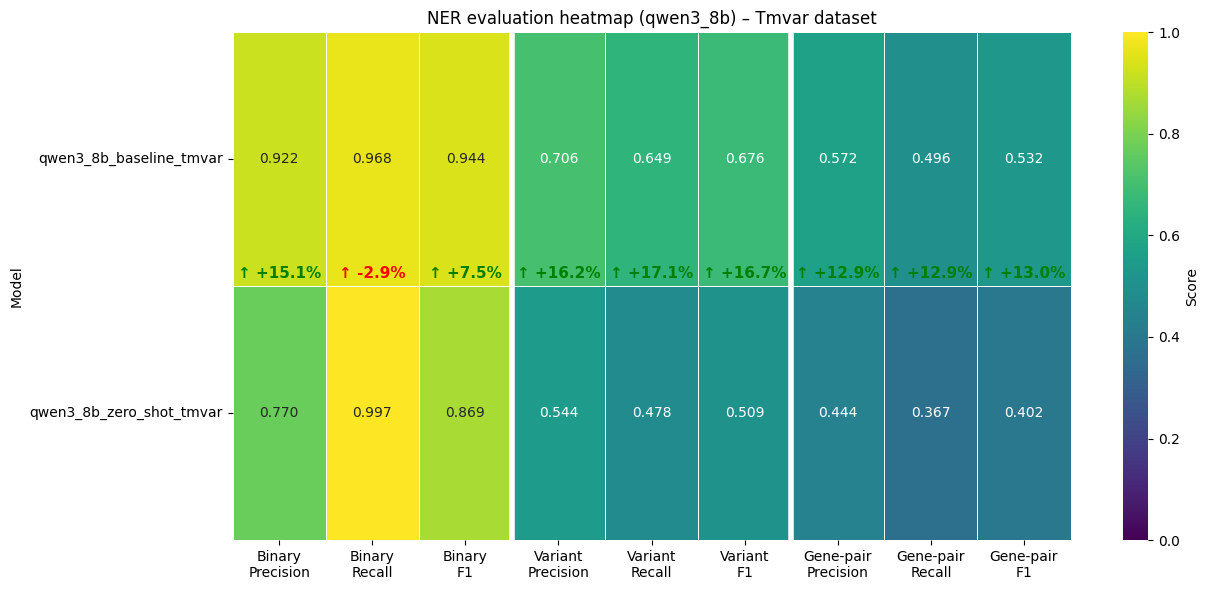

In [14]:
import numpy as np

# Ensure correct ordering
sort_column = "Gene-pair\nF1"
if sort_column in heatmap_df.columns:
    heatmap_df = heatmap_df.sort_values(sort_column, ascending=False)

plt.figure(figsize=(13, max(6, 0.45 * len(heatmap_df))))

ax = sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    vmin=0,
    vmax=1,
    cmap="viridis",
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Score"},
)

# ------------------------------------------------------------
# Add % deltas BETWEEN rows (not inside cells)
# ------------------------------------------------------------
n_rows, n_cols = heatmap_df.shape

for i in range(n_rows - 1):
    upper = heatmap_df.iloc[i]
    lower = heatmap_df.iloc[i + 1]

    pct_change = (upper - lower) * 100 #(upper - lower) / lower.replace(0, np.nan) * 100

    # y position BETWEEN rows
    y = i + 0.95

    for j in range(n_cols):
        x = j + 0.5

        val = pct_change.iloc[j]
        if np.isnan(val):
            continue

        color = "black"
        if val >= 0:
            color = "green"
        else:
            color = "red"

        ax.text(
            x,
            y,
            f"↑ {val:+.1f}%",
            ha="center",
            va="center",
            fontsize=11,
            color=color,
            fontweight="bold",
        )

# Task separators
for xpos in [3, 6]:
    ax.axvline(xpos, color="white", linewidth=4)

plt.title(f"NER evaluation heatmap ({MODEL_FAMILY}) – {DATASET.capitalize()} dataset")
plt.xlabel("")
plt.ylabel("Model")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Error analysis

In [66]:
import pandas as pd

PATH = "../data/evaluation_train_on_hered_5ep"
MODEL = "llama31_8b"
TEST_SET = "tmvar"

vt_errors = pd.read_csv(f'{PATH}/{MODEL}_vt_{TEST_SET}/per_example_errors.csv')
vt_errors = vt_errors[["user", "target", "prediction", "missing_variants", "extra_variants", "missing_pairs", "extra_pairs"]]
bl_errors = pd.read_csv(f'{PATH}/{MODEL}_baseline_{TEST_SET}/per_example_errors.csv')
bl_errors = bl_errors[["user", "target", "prediction", "missing_variants", "extra_variants", "missing_pairs", "extra_pairs"]]

df_errors = pd.merge(bl_errors, vt_errors, on=['user', 'target'], how='outer')
df_errors = df_errors.rename(columns={c: c.replace("_x", "_bl") for c in df_errors.columns if c.endswith("_x")})
df_errors = df_errors.rename(columns={c: c.replace("_y", "_vt") for c in df_errors.columns if c.endswith("_y")})
df_errors.to_csv("~/Downloads/df_errors.csv", index=False)
df_errors

,user,target,prediction_bl,missing_variants_bl,extra_variants_bl,missing_pairs_bl,extra_pairs_bl,prediction_vt,missing_variants_vt,extra_variants_vt,missing_pairs_vt,extra_pairs_vt
0,Title: Screening and cell-based assessment of ...,"Variant: c.304ins(GCG)(7), Gene: ARX\nVariant:...",Variant: c.304ins(GCG)( 7 ) ' expansion ' of p...,c.304ins(gcg)(7) | c.429_452dup | dup24bp | du...,c.304ins(gcg)(7)'expansion'ofpa1 | c.429_452du...,c.304ins(gcg)(7)::arx | c.429_452dup::arx | du...,c.304ins(gcg)(7)'expansion'ofpa1::arx | c.429_...,"Variant: c.304ins(GCG)( 7 )'expansion' of pA1,...",c.304ins(gcg)(7) | c.429_452dup | dup24bp,c.304ins(gcg)(7)'expansion'ofpa1 | c.429_452du...,c.304ins(gcg)(7)::arx | c.429_452dup::arx | du...,c.304ins(gcg)(7)'expansion'ofpa1::arx | c.429_...
1,Title: High frequency of lamivudine resistance...,"Variant: L180M, Gene: polymerase\nVariant: M20...","Variant: rsL180M, Gene: LAM\nVariant: rsM204V,...",e164d | i195m | l180m | m204v | v173l,rsl180m | rsm204v | rsv173l,a1762t::precore | e164d::envelope | g1764a::pr...,a1762t::bcp | g1764a::bcp | rsl180m::lam | rsm...,"Variant: rtL180M + rtM204V, Gene: Unknown\nVar...",e164d | i195m | l180m | m204v | v173l,rtl180m+rtm204v | rtv173l | se164d+si195m,a1762t::precore | e164d::envelope | g1764a::pr...,a1762t::unknown | g1764a::unknown | g1896a::un...
2,Title: FGFR4 Gly388Arg polymorphism and prosta...,"Variant: Gly388Arg, Gene: FGFR4\nVariant: Gly(...","Variant: Gly388Arg, Gene: FGFR4\nVariant: ArgA...",NaN,argarg | glygly,NaN,argarg::fgfr4 | glygly::fgfr4,NaN,NaN,NaN,NaN,NaN
3,Title: DNA repair gene polymorphisms in relati...,"Variant: R194W, Gene: XRCC1\nVariant: R399Q, G...","Variant: R194W, Gene: XRCC1\nVariant: R399Q, G...",[ac]n | gactanmicrosatellitelocated120kb,NaN,[ac]n::xrcc1 | [ac]n::xrcc3 | gactanmicrosatel...,NaN,"Variant: R194W, Gene: XRCC1\nVariant: R399Q, G...",[ac]n | gactanmicrosatellitelocated120kb,NaN,[ac]n::xrcc1 | [ac]n::xrcc3 | gactanmicrosatel...,NaN
4,Title: Nucleotide mutations associated with he...,"Variant: G529A, Gene: HBeAg\nVariant: C934A, G...","Variant: G529A, Gene: Unknown\nVariant: C934A,...",NaN,NaN,a1053g::hbeag | c3026t::hbeag | c934a::hbeag |...,a1053g::unknown | c3026t::unknown | c934a::unk...,"Variant: G529A, Gene: Unknown\nVariant: C934A,...",NaN,NaN,a1053g::hbeag | c3026t::hbeag | c934a::hbeag |...,a1053g::unknown | c3026t::unknown | c934a::unk...
5,Title: Nijmegen breakage syndrome in 13% of ag...,"Variant: 5 nucleotide deletion, Gene: NBS1",No variant,5nucleotidedeletion,NaN,5nucleotidedeletion::nbs1,NaN,NaN,NaN,NaN,NaN,NaN
6,Title: Genetic variation in apolipoprotein D a...,"Variant: 15T-->C, Gene: APOD\nVariant: Phe-->S...","Variant: 15T-->C, Gene: APOD\nVariant: Phe-->S...","intron2,-352g-->a | intron3,+45c-->t | intron4...",+45c-->t | +718c-->t | -352g-->a | phe-->ser,"intron2,-352g-->a::apod | intron3,+45c-->t::ap...",+45c-->t::apod | +718c-->t::apod | -352g-->a::...,"Variant: 15T-->C, Gene: APOD\nVariant: Phe-->S...","intron2,-352g-->a | intron3,+45c-->t | intron4...",+45c--/t | +718c--/t | -352g | -352g--/a | phe...,"intron2,-352g-->a::apod | intron3,+45c-->t::ap...",+45c--/t::apod | +718c--/t::apod | -352g::abod...
7,Title: Novel mutations identification in exon ...,"Variant: p.E180K, Gene: LDLR\nVariant: p.R194S...","Variant: p.E180K, Gene: LDLR\nVariant: p.R194S...",NaN,NaN,p.d157fsx158::ldlr | p.s173fsx174::ldlr,p.d157fsx158::apob | p.s173fsx174::apob,"Variant: p.E180K, Gene: LDLR\nVariant: p.R194S...",p.s173fsx174,NaN,p.d157fsx158::ldlr | p.s173fsx174::ldlr,"p.d157fsx158::p.s173fsx174, gene: p.d157fsx158"
8,Title: Familial pycnodysostosis: identificatio...,"Variant: c.908G>A, Gene: CTSK\nVariant: glycin...","Variant: c.908G>A, Gene: CTSK\nVariant: substi...",glycineatposition303byglutamicacid,substitutionoftheaminoacidglycineatposition303...,g303e::cathepsin k | glycineatposition303byglu...,g303e::ctsk | substitutionoftheaminoacidglycin...,"Variant: c.908G>A, Gene: CTSK\nVariant: substi...",glycineatposition30

In [69]:
df_errors_missing_v = df_errors[["missing_variants_bl", "missing_variants_vt"]]
df_errors_missing_v = df_errors_missing_v.dropna(how='all')
#df_errors_missing_v = df_errors_missing_v[df_errors_missing_v['missing_variants_bl'] != df_errors_missing_v['missing_variants_vt']]

miss_bl = set(df_errors_missing_v['missing_variants_bl'].str.split(r"\s*\|\s*").explode('missing_variants_bl'))
miss_vt = set(df_errors_missing_v['missing_variants_vt'].str.split(r"\s*\|\s*").explode('missing_variants_vt'))

#df_errors_missing_p

miss_vt - miss_bl

{'arginine150proline',
 'gtocsubstitutionatposition-174',
 'p.s173fsx174',
 'serinebyprolineatcodon1235'}

In [65]:
df_errors_extra_v = df_errors[["extra_variants_bl", "extra_variants_vt"]]
df_errors_extra_v = df_errors_extra_v.dropna(how='all')
df_errors_extra_v = df_errors_extra_v[df_errors_extra_v['extra_variants_bl'] != df_errors_extra_v['extra_variants_vt']]

extra_bl = set(df_errors_extra_v['extra_variants_bl'].str.split(r"\s*\|\s*").explode('extra_variants_bl'))
extra_vt = set(df_errors_extra_v['extra_variants_vt'].str.split(r"\s*\|\s*").explode('extra_variants_vt'))

extra_vt - extra_bl

{'114-kda',
 '11p13',
 '1or5¥ìm',
 '80kda',
 'alatothrsubstitution',
 'argtoglnsubstitution',
 'codon117',
 'codon12',
 'codon12and13',
 'codon146',
 'codon164',
 'codon173',
 'codon19',
 'codon61',
 'ctotnucleotidesubstitution,whichdidnotaltertheasparticacidresidueatcodon173',
 'deletioninexon19',
 'gtoachange',
 'ileäe746?a750',
 'l858r/t790m',
 'lystoasnsubstitution',
 'ttoatransversion',
 'valinetoglutamicacidsubstitution'}

In [57]:
df_errors_missing_p = df_errors[["missing_pairs_bl", "missing_pairs_vt"]]
df_errors_missing_p = df_errors_missing_p.dropna(how='all')

miss_bl = set(df_errors_missing_p['missing_pairs_bl'].str.split(r"\s*\|\s*").explode('missing_pairs_bl'))
miss_vt = set(df_errors_missing_p['missing_pairs_vt'].str.split(r"\s*\|\s*").explode('missing_pairs_vt'))

#df_errors_missing_p

miss_bl - miss_vt

{'a146t::k-ras',
 'g12v::kras',
 'g13d::k-ras',
 'g57t::k-ras',
 'k117n::k-ras',
 'l19f::k-ras',
 'leu19phe::k-ras',
 'q61h::k-ras',
 'q61h::kras'}

## Plot training curves

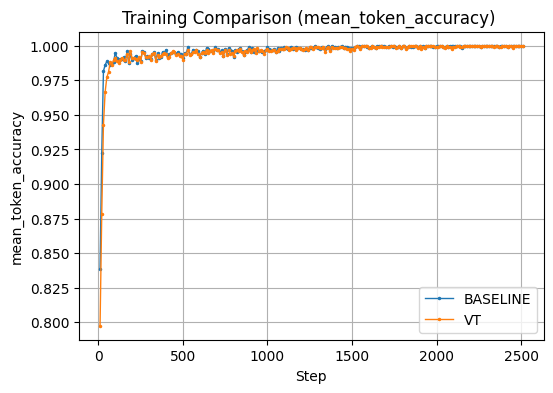

In [19]:
import json
import matplotlib.pyplot as plt

PROPERTY = "mean_token_accuracy"
MODEL = "qwen3_8b"
BASE_PATH = "../evaluation/training_logs"
CONTRASTIVE = False

FILE_NAME = "train_step_logs.jsonl" if CONTRASTIVE else "log_history.jsonl"

RUN_1 = "baseline"
RUN_2 = "vt"


def load_curve(path):
    data = []
    
    with open(path, "r") as f:
        if CONTRASTIVE:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                data.append(json.loads(line))
        else:
            data = json.load(f)

    steps = [x["step"] for x in data if PROPERTY in x]
    values = [x[PROPERTY] for x in data if PROPERTY in x]

    return steps, values


suffix = "_contrastive" if CONTRASTIVE else ""

path1 = f"{BASE_PATH}/{MODEL}_{RUN_1}{suffix}/{FILE_NAME}"
path2 = f"{BASE_PATH}/{MODEL}_{RUN_2}{suffix}/{FILE_NAME}"

steps1, acc1 = load_curve(path1)
steps2, acc2 = load_curve(path2)

plt.figure(figsize=(6, 4))

plt.plot(steps1, acc1, marker="o", markersize=1.5, linewidth=1, label=RUN_1.upper())
plt.plot(steps2, acc2, marker="o", markersize=1.5, linewidth=1, label=RUN_2.upper())

plt.xlabel("Step")
plt.ylabel("recall@1" if PROPERTY == "train_recall_at_1_running" else PROPERTY)
plt.title(f"Training Comparison{f' ({PROPERTY}) ' if CONTRASTIVE == False else ''}")
plt.legend()
plt.grid(True)

plt.show()

## Performance improvements

Loaded runs:


,dataset,dataset_label,score,model,base_strategy,warmup,contrastive,condition
21,bronco,BRONCO,0.864241,baseline,baseline,False,False,baseline
23,bronco,BRONCO,0.030683,baseline_contrastive,baseline,False,True,baseline + contrastive
25,bronco,BRONCO,0.424073,baseline_after_warm,baseline,True,False,baseline + warmup
22,bronco,BRONCO,0.847304,vt,vt,False,False,vt
26,bronco,BRONCO,0.680902,vt_contrastive,vt,False,True,vt + contrastive
24,bronco,BRONCO,0.847834,vt_after_warm,vt,True,False,vt + warmup
27,bronco,BRONCO,0.828389,vt_after_warm_contrastive,vt,True,True,vt + warmup + contrastive
4,hered,Hered,0.798162,baseline,baseline,False,False,baseline
1,hered,Hered,0.193732,baseline_contrastive,baseline,False,True,baseline + contrastive
0,hered,Hered,0.555133,baseline_after_warm,baseline,True,False,baseline + warmup


Computed effects:


,dataset,dataset_label,condition_added,delta,comparison
39,bronco,BRONCO,Contrastive,-0.833557,baseline_contrastive − baseline
41,bronco,BRONCO,Contrastive,-0.019445,vt_after_warm_contrastive − vt_after_warm
40,bronco,BRONCO,Contrastive,-0.166402,vt_contrastive − vt
30,hered,Hered,Contrastive,-0.604430,baseline_contrastive − baseline
32,hered,Hered,Contrastive,-0.285677,vt_after_warm_contrastive − vt_after_warm
31,hered,Hered,Contrastive,-0.201526,vt_contrastive − vt
42,tmvar,TmVar,Contrastive,-0.642479,baseline_contrastive − baseline
44,tmvar,TmVar,Contrastive,-0.134038,vt_after_warm_contrastive − vt_after_warm
43,tmvar,TmVar,Contrastive,-0.163938,vt_contrastive − vt
33,varchat,Varchat,Contrastive,-0.555556,baseline_contrastive − baseline


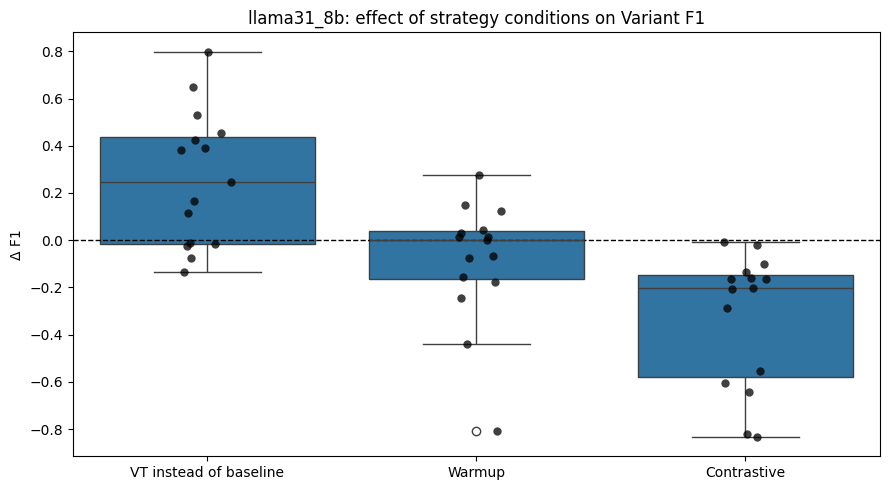

In [4]:
from pathlib import Path
import json
import re

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# =========================
# Configuration
# =========================

MODEL_FAMILY = "llama31_8b"
BASE_DIR = Path("../evaluation")

APPLY_ADJ = False
METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"

DATASETS = ["hered", "varchat", "variantscape", "bronco", "tmvar"]

# Choose the metric to analyze
TASK = "variant_extraction_micro"
SCORE = "f1"

TASK_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

DATASET_LABELS = {
    "hered": "Hered",
    "varchat": "Varchat",
    "variantscape": "VariantScape",
    "bronco": "BRONCO",
    "tmvar": "TmVar",
}


# =========================
# Helpers
# =========================

def parse_model_name(model_name):
    """
    Parses strategy conditions from names such as:

        baseline
        baseline_after_warm
        baseline_contrastive
        baseline_after_warm_contrastive
        vt
        vt_after_warm
        vt_contrastive
        vt_after_warm_contrastive

    Returns:
        dict with base_strategy, warmup, contrastive
    """

    if model_name.startswith("baseline"):
        base_strategy = "baseline"
    elif model_name.startswith("vt"):
        base_strategy = "vt"
    else:
        return None

    warmup = "after_warm" in model_name
    contrastive = model_name.endswith("contrastive")

    return {
        "model": model_name,
        "base_strategy": base_strategy,
        "warmup": warmup,
        "contrastive": contrastive,
    }


def format_condition_name(row):
    parts = [row["base_strategy"]]

    if row["warmup"]:
        parts.append("warmup")

    if row["contrastive"]:
        parts.append("contrastive")

    return " + ".join(parts)


# =========================
# Load all available runs
# =========================

rows = []

for dataset in DATASETS:
    pattern = f"{MODEL_FAMILY}_*_{dataset}"

    for run_dir in BASE_DIR.glob(pattern):
        if not run_dir.is_dir():
            continue

        metrics_path = run_dir / METRICS_FILE
        if not metrics_path.exists():
            continue

        # Remove model family prefix and dataset suffix
        prefix = f"{MODEL_FAMILY}_"
        suffix = f"_{dataset}"

        run_name = run_dir.name

        if not run_name.startswith(prefix) or not run_name.endswith(suffix):
            continue

        model_name = run_name[len(prefix):-len(suffix)]

        parsed = parse_model_name(model_name)
        if parsed is None:
            continue

        with open(metrics_path) as f:
            metrics = json.load(f)

        rows.append(
            {
                "dataset": dataset,
                "dataset_label": DATASET_LABELS.get(dataset, dataset),
                "score": metrics[TASK][SCORE],
                **parsed,
            }
        )

df = pd.DataFrame(rows)

if df.empty:
    raise ValueError("No matching runs found. Check BASE_DIR, MODEL_FAMILY, DATASETS, and METRICS_FILE.")

df["condition"] = df.apply(format_condition_name, axis=1)

print("Loaded runs:")
display(
    df.sort_values(["dataset", "base_strategy", "warmup", "contrastive"])
)


# =========================
# Compute condition effects
# =========================

effects = []

# 1. Effect of using vt instead of baseline
# Compare vt vs baseline with the same warmup/contrastive setting.
for dataset in DATASETS:
    subset = df[df["dataset"] == dataset]

    for warmup in [False, True]:
        for contrastive in [False, True]:
            lhs = subset[
                (subset["base_strategy"] == "vt")
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == contrastive)
            ]

            rhs = subset[
                (subset["base_strategy"] == "baseline")
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == contrastive)
            ]

            if len(lhs) == 1 and len(rhs) == 1:
                effects.append(
                    {
                        "dataset": dataset,
                        "dataset_label": DATASET_LABELS.get(dataset, dataset),
                        "condition_added": "VT instead of baseline",
                        "delta": lhs["score"].iloc[0] - rhs["score"].iloc[0],
                        "comparison": (
                            f"vt"
                            f"{'_after_warm' if warmup else ''}"
                            f"{'_contrastive' if contrastive else ''}"
                            " − "
                            f"baseline"
                            f"{'_after_warm' if warmup else ''}"
                            f"{'_contrastive' if contrastive else ''}"
                        ),
                    }
                )


# 2. Effect of warmup
# Compare *_after_warm vs same setup without warmup.
for dataset in DATASETS:
    subset = df[df["dataset"] == dataset]

    for base_strategy in ["baseline", "vt"]:
        for contrastive in [False, True]:
            lhs = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == True)
                & (subset["contrastive"] == contrastive)
            ]

            rhs = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == False)
                & (subset["contrastive"] == contrastive)
            ]

            if len(lhs) == 1 and len(rhs) == 1:
                effects.append(
                    {
                        "dataset": dataset,
                        "dataset_label": DATASET_LABELS.get(dataset, dataset),
                        "condition_added": "Warmup",
                        "delta": lhs["score"].iloc[0] - rhs["score"].iloc[0],
                        "comparison": (
                            f"{base_strategy}_after_warm"
                            f"{'_contrastive' if contrastive else ''}"
                            " − "
                            f"{base_strategy}"
                            f"{'_contrastive' if contrastive else ''}"
                        ),
                    }
                )


# 3. Effect of contrastive
# Compare *_contrastive vs same setup without contrastive.
for dataset in DATASETS:
    subset = df[df["dataset"] == dataset]

    for base_strategy in ["baseline", "vt"]:
        for warmup in [False, True]:
            lhs = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == True)
            ]

            rhs = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == False)
            ]

            if len(lhs) == 1 and len(rhs) == 1:
                effects.append(
                    {
                        "dataset": dataset,
                        "dataset_label": DATASET_LABELS.get(dataset, dataset),
                        "condition_added": "Contrastive",
                        "delta": lhs["score"].iloc[0] - rhs["score"].iloc[0],
                        "comparison": (
                            f"{base_strategy}"
                            f"{'_after_warm' if warmup else ''}"
                            "_contrastive"
                            " − "
                            f"{base_strategy}"
                            f"{'_after_warm' if warmup else ''}"
                        ),
                    }
                )


effects_df = pd.DataFrame(effects)

if effects_df.empty:
    raise ValueError(
        "No valid paired comparisons found. "
        "Make sure matching runs exist for baseline/vt, warmup/non-warmup, and contrastive/non-contrastive."
    )

print("Computed effects:")
display(effects_df.sort_values(["condition_added", "dataset", "comparison"]))


# =========================
# Boxplot
# =========================

condition_order = [
    "VT instead of baseline",
    "Warmup",
    "Contrastive",
]

plt.figure(figsize=(9, 5))

ax = sns.boxplot(
    data=effects_df,
    x="condition_added",
    y="delta",
    order=condition_order,
)

sns.stripplot(
    data=effects_df,
    x="condition_added",
    y="delta",
    order=condition_order,
    color="black",
    size=6,
    alpha=0.75,
    jitter=True,
)

ax.axhline(0, color="black", linewidth=1, linestyle="--")

title = f"{MODEL_FAMILY}: effect of strategy conditions on {TASK_LABELS[TASK]} {SCORE_LABELS[SCORE]}"

plt.title(title)
plt.xlabel("")
plt.ylabel(f"Δ {SCORE_LABELS[SCORE]}")

plt.tight_layout()
plt.show()

Loaded runs:


,dataset,dataset_label,score,model,training_regime,base_strategy,warmup,contrastive
27,bronco,BRONCO,0.877131,baseline,fine-tuned,baseline,False,False
30,bronco,BRONCO,0.015625,baseline_contrastive,fine-tuned,baseline,False,True
32,bronco,BRONCO,0.377841,baseline_after_warm,fine-tuned,baseline,True,False
28,bronco,BRONCO,0.377841,baseline_after_warm_contrastive,fine-tuned,baseline,True,True
29,bronco,BRONCO,0.865057,vt,fine-tuned,vt,False,False
33,bronco,BRONCO,0.600142,vt_contrastive,fine-tuned,vt,False,True
31,bronco,BRONCO,0.840909,vt_after_warm,fine-tuned,vt,True,False
34,bronco,BRONCO,0.783381,vt_after_warm_contrastive,fine-tuned,vt,True,True
35,bronco,BRONCO,0.377841,zero_shot,zero-shot,zero_shot,False,False
6,hered,Hered,0.713203,baseline,fine-tuned,baseline,False,False


Paired before/after values:


,dataset,dataset_label,strategy_factor,factor_level,score,comparison
127,bronco,BRONCO,Contrastive learning,After,0.377841,baseline_after_warm_contrastive vs baseline_af...
126,bronco,BRONCO,Contrastive learning,Before,0.377841,baseline_after_warm_contrastive vs baseline_af...
125,bronco,BRONCO,Contrastive learning,After,0.015625,baseline_contrastive vs baseline
124,bronco,BRONCO,Contrastive learning,Before,0.877131,baseline_contrastive vs baseline
131,bronco,BRONCO,Contrastive learning,After,0.783381,vt_after_warm_contrastive vs vt_after_warm
...,...,...,...,...,...,...
78,variantscape,VariantScape,Warmup,Before,0.000000,baseline_after_warm_contrastive vs baseline_co...
81,variantscape,VariantScape,Warmup,After,0.836364,vt_after_warm vs vt
80,variantscape,VariantScape,Warmup,Before,0.927273,vt_after_warm vs vt
83,variantscape,VariantScape,Warmup,After,0.763636,vt_after_warm_contrastive vs vt_contrastive


Paired differences:


,dataset,dataset_label,strategy_factor,delta,comparison
63,bronco,BRONCO,Contrastive learning,0.000000,baseline_after_warm_contrastive vs baseline_af...
62,bronco,BRONCO,Contrastive learning,-0.861506,baseline_contrastive vs baseline
65,bronco,BRONCO,Contrastive learning,-0.057528,vt_after_warm_contrastive vs vt_after_warm
64,bronco,BRONCO,Contrastive learning,-0.264915,vt_contrastive vs vt
51,hered,Hered,Contrastive learning,0.000000,baseline_after_warm_contrastive vs baseline_af...
...,...,...,...,...,...
37,varchat,Varchat,Warmup,-0.071429,vt_after_warm_contrastive vs vt_contrastive
38,variantscape,VariantScape,Warmup,-0.581818,baseline_after_warm vs baseline
39,variantscape,VariantScape,Warmup,0.345455,baseline_after_warm_contrastive vs baseline_co...
40,variantscape,VariantScape,Warmup,-0.090909,vt_after_warm vs vt


/var/folders/57/yk3w62md44z9m6ndy61mkkz80000gn/T/ipykernel_2777/3240920099.py:460: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


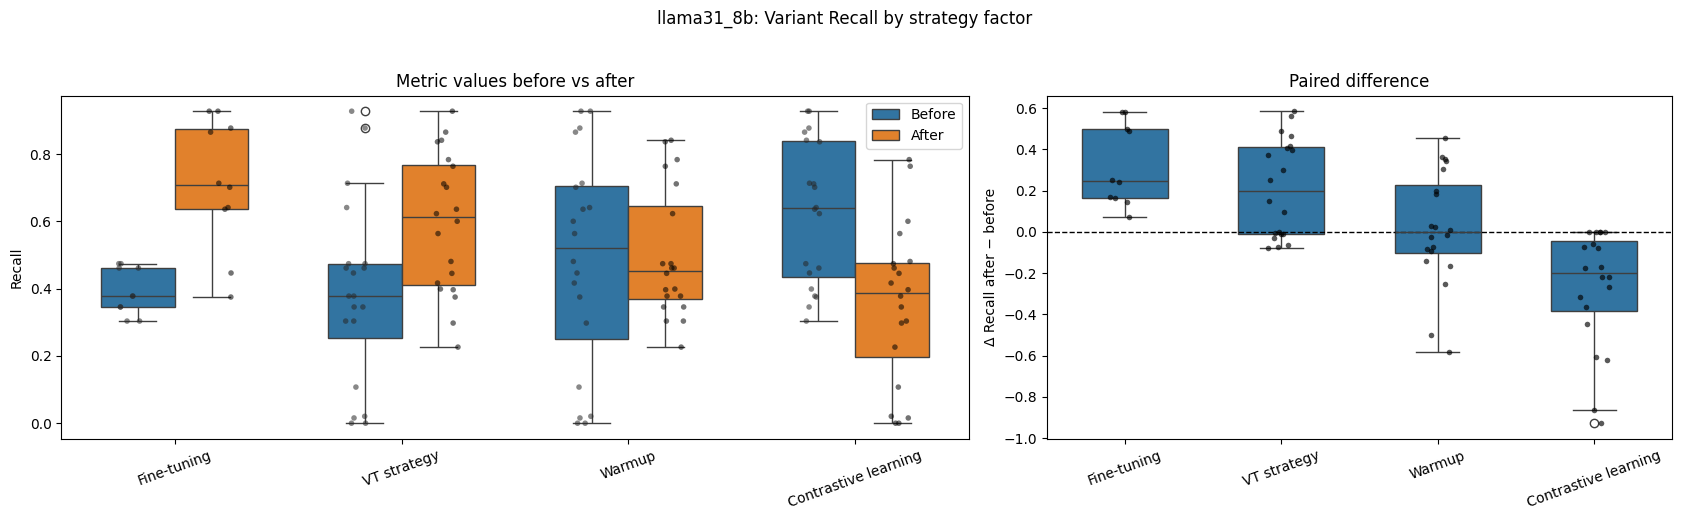

In [ ]:
from pathlib import Path
import json

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# =========================
# Configuration
# =========================

MODEL_FAMILY = "llama31_8b"
BASE_DIR = Path("../evaluation")

APPLY_ADJ = False
METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"

DATASETS = ["hered", "varchat", "variantscape", "bronco", "tmvar"]

# Choose the metric to analyze
TASK = "variant_extraction_micro"
SCORE = "recall"

TASK_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

DATASET_LABELS = {
    "hered": "Hered",
    "varchat": "Varchat",
    "variantscape": "VariantScape",
    "bronco": "BRONCO",
    "tmvar": "TmVar",
}


# =========================
# Helpers
# =========================

def parse_model_name(model_name):
    """
    Parses strategy setup from names such as:

        zero_shot

        baseline
        baseline_after_warm
        baseline_contrastive
        baseline_after_warm_contrastive

        vt
        vt_after_warm
        vt_contrastive
        vt_after_warm_contrastive

    Interpretation:
        - zero_shot means non-finetuned
        - all other recognized models are finetuned
    """

    if model_name == "zero_shot":
        return {
            "model": model_name,
            "training_regime": "zero-shot",
            "base_strategy": "zero_shot",
            "warmup": False,
            "contrastive": False,
        }

    if model_name.startswith("baseline"):
        base_strategy = "baseline"
    elif model_name.startswith("vt"):
        base_strategy = "vt"
    else:
        return None

    warmup = "after_warm" in model_name
    contrastive = model_name.endswith("contrastive")

    return {
        "model": model_name,
        "training_regime": "fine-tuned",
        "base_strategy": base_strategy,
        "warmup": warmup,
        "contrastive": contrastive,
    }


def add_pair(paired_rows, deltas, dataset, strategy_factor, before_row, after_row, comparison):
    """
    Adds both raw before/after scores and paired after-before delta.
    """

    dataset_label = DATASET_LABELS.get(dataset, dataset)

    before_score = before_row["score"].iloc[0]
    after_score = after_row["score"].iloc[0]
    delta = after_score - before_score

    paired_rows.append(
        {
            "dataset": dataset,
            "dataset_label": dataset_label,
            "strategy_factor": strategy_factor,
            "factor_level": "Before",
            "score": before_score,
            "comparison": comparison,
        }
    )

    paired_rows.append(
        {
            "dataset": dataset,
            "dataset_label": dataset_label,
            "strategy_factor": strategy_factor,
            "factor_level": "After",
            "score": after_score,
            "comparison": comparison,
        }
    )

    deltas.append(
        {
            "dataset": dataset,
            "dataset_label": dataset_label,
            "strategy_factor": strategy_factor,
            "delta": delta,
            "comparison": comparison,
        }
    )


# =========================
# Load all available runs
# =========================

rows = []

for dataset in DATASETS:
    pattern = f"{MODEL_FAMILY}_*_{dataset}"

    for run_dir in BASE_DIR.glob(pattern):
        if not run_dir.is_dir():
            continue

        metrics_path = run_dir / METRICS_FILE
        if not metrics_path.exists():
            continue

        prefix = f"{MODEL_FAMILY}_"
        suffix = f"_{dataset}"

        run_name = run_dir.name

        if not run_name.startswith(prefix) or not run_name.endswith(suffix):
            continue

        model_name = run_name[len(prefix):-len(suffix)]

        parsed = parse_model_name(model_name)
        if parsed is None:
            continue

        with open(metrics_path) as f:
            metrics = json.load(f)

        rows.append(
            {
                "dataset": dataset,
                "dataset_label": DATASET_LABELS.get(dataset, dataset),
                "score": metrics[TASK][SCORE],
                **parsed,
            }
        )

df = pd.DataFrame(rows)

if df.empty:
    raise ValueError(
        "No matching runs found. Check BASE_DIR, MODEL_FAMILY, DATASETS, and METRICS_FILE."
    )

print("Loaded runs:")
display(
    df.sort_values(
        [
            "dataset",
            "training_regime",
            "base_strategy",
            "warmup",
            "contrastive",
        ]
    )
)


# =========================
# Build paired before/after values
# =========================

paired_rows = []
deltas = []


# -------------------------
# 1. Fine-tuning
# -------------------------
# Before: zero_shot
# After: baseline or vt only
#
# IMPORTANT:
# This excludes warmup and contrastive variants.
# Only these fine-tuned models are used:
#   - baseline
#   - vt
# -------------------------

for dataset in DATASETS:
    subset = df[df["dataset"] == dataset]

    before = subset[subset["model"] == "zero_shot"]

    after_candidates = subset[
        (subset["training_regime"] == "fine-tuned")
        & (subset["base_strategy"].isin(["baseline", "vt"]))
        & (subset["warmup"] == False)
        & (subset["contrastive"] == False)
    ]

    if len(before) == 1:
        for _, after_candidate in after_candidates.iterrows():
            after = after_candidates[after_candidates["model"] == after_candidate["model"]]

            comparison = f"{after_candidate['model']} vs zero_shot"

            add_pair(
                paired_rows=paired_rows,
                deltas=deltas,
                dataset=dataset,
                strategy_factor="Fine-tuning",
                before_row=before,
                after_row=after,
                comparison=comparison,
            )


# -------------------------
# 2. VT instead of baseline
# -------------------------
# Before: baseline
# After: vt
# Matched by dataset, warmup, and contrastive.
# -------------------------

for dataset in DATASETS:
    subset = df[df["dataset"] == dataset]

    for warmup in [False, True]:
        for contrastive in [False, True]:
            before = subset[
                (subset["base_strategy"] == "baseline")
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == contrastive)
            ]

            after = subset[
                (subset["base_strategy"] == "vt")
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == contrastive)
            ]

            if len(before) == 1 and len(after) == 1:
                comparison = (
                    f"vt"
                    f"{'_after_warm' if warmup else ''}"
                    f"{'_contrastive' if contrastive else ''}"
                    " vs "
                    f"baseline"
                    f"{'_after_warm' if warmup else ''}"
                    f"{'_contrastive' if contrastive else ''}"
                )

                add_pair(
                    paired_rows=paired_rows,
                    deltas=deltas,
                    dataset=dataset,
                    strategy_factor="VT strategy",
                    before_row=before,
                    after_row=after,
                    comparison=comparison,
                )


# -------------------------
# 3. Warmup
# -------------------------
# Before: no warmup
# After: after_warm
# Matched by dataset, base strategy, and contrastive.
# -------------------------

for dataset in DATASETS:
    subset = df[df["dataset"] == dataset]

    for base_strategy in ["baseline", "vt"]:
        for contrastive in [False, True]:
            before = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == False)
                & (subset["contrastive"] == contrastive)
            ]

            after = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == True)
                & (subset["contrastive"] == contrastive)
            ]

            if len(before) == 1 and len(after) == 1:
                comparison = (
                    f"{base_strategy}_after_warm"
                    f"{'_contrastive' if contrastive else ''}"
                    " vs "
                    f"{base_strategy}"
                    f"{'_contrastive' if contrastive else ''}"
                )

                add_pair(
                    paired_rows=paired_rows,
                    deltas=deltas,
                    dataset=dataset,
                    strategy_factor="Warmup",
                    before_row=before,
                    after_row=after,
                    comparison=comparison,
                )


# -------------------------
# 4. Contrastive
# -------------------------
# Before: no contrastive
# After: contrastive
# Matched by dataset, base strategy, and warmup.
# -------------------------

for dataset in DATASETS:
    subset = df[df["dataset"] == dataset]

    for base_strategy in ["baseline", "vt"]:
        for warmup in [False, True]:
            before = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == False)
            ]

            after = subset[
                (subset["base_strategy"] == base_strategy)
                & (subset["warmup"] == warmup)
                & (subset["contrastive"] == True)
            ]

            if len(before) == 1 and len(after) == 1:
                comparison = (
                    f"{base_strategy}"
                    f"{'_after_warm' if warmup else ''}"
                    "_contrastive"
                    " vs "
                    f"{base_strategy}"
                    f"{'_after_warm' if warmup else ''}"
                )

                add_pair(
                    paired_rows=paired_rows,
                    deltas=deltas,
                    dataset=dataset,
                    strategy_factor="Contrastive learning",
                    before_row=before,
                    after_row=after,
                    comparison=comparison,
                )


paired_df = pd.DataFrame(paired_rows)
delta_df = pd.DataFrame(deltas)

if paired_df.empty or delta_df.empty:
    raise ValueError(
        "No valid paired comparisons found. "
        "Make sure matching runs exist for zero_shot, baseline/vt, warmup/non-warmup, "
        "and contrastive/non-contrastive."
    )

print("Paired before/after values:")
display(
    paired_df.sort_values(
        ["strategy_factor", "dataset", "comparison", "factor_level"]
    )
)

print("Paired differences:")
display(
    delta_df.sort_values(
        ["strategy_factor", "dataset", "comparison"]
    )
)


# =========================
# Plot: before/after + delta
# =========================

strategy_order = [
    "Fine-tuning",
    "VT strategy",
    "Warmup",
    "Contrastive learning",
]

level_order = [
    "Before",
    "After",
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 5),
    gridspec_kw={"width_ratios": [1.45, 1]},
)

# -------------------------
# Left plot: raw scores before vs after
# -------------------------

ax = axes[0]

sns.boxplot(
    data=paired_df,
    x="strategy_factor",
    y="score",
    hue="factor_level",
    order=strategy_order,
    hue_order=level_order,
    width=0.65,
    ax=ax,
)

sns.stripplot(
    data=paired_df,
    x="strategy_factor",
    y="score",
    hue="factor_level",
    order=strategy_order,
    hue_order=level_order,
    dodge=True,
    color="black",
    size=4,
    alpha=0.55,
    ax=ax,
)

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[:2],
    labels[:2],
    title="",
    loc="best",
)

ax.set_title("Metric values before vs after")
ax.set_xlabel("")
ax.set_ylabel(SCORE_LABELS[SCORE])
ax.tick_params(axis="x", rotation=20)


# -------------------------
# Right plot: paired differences
# -------------------------

ax = axes[1]

sns.boxplot(
    data=delta_df,
    x="strategy_factor",
    y="delta",
    order=strategy_order,
    width=0.55,
    ax=ax,
)

sns.stripplot(
    data=delta_df,
    x="strategy_factor",
    y="delta",
    order=strategy_order,
    color="black",
    size=4,
    alpha=0.65,
    jitter=True,
    ax=ax,
)

ax.axhline(0, color="black", linewidth=1, linestyle="--")

ax.set_title("Paired difference")
ax.set_xlabel("")
ax.set_ylabel(f"Δ {SCORE_LABELS[SCORE]} after − before")
ax.tick_params(axis="x", rotation=20)


# -------------------------
# Overall title
# -------------------------

fig.suptitle(
    f"{MODEL_FAMILY}: {TASK_LABELS[TASK]} {SCORE_LABELS[SCORE]} by strategy factor",
    y=1.03,
)

plt.tight_layout()
plt.show()

Loaded runs for llama31_8b:


,model_family,dataset,dataset_label,score,model,training_regime,base_strategy,warmup,contrastive
27,llama31_8b,bronco,BRONCO,0.536932,baseline,fine-tuned,baseline,False,False
30,llama31_8b,bronco,BRONCO,0.004972,baseline_contrastive,fine-tuned,baseline,False,True
32,llama31_8b,bronco,BRONCO,0.301136,baseline_after_warm,fine-tuned,baseline,True,False
28,llama31_8b,bronco,BRONCO,0.301136,baseline_after_warm_contrastive,fine-tuned,baseline,True,True
29,llama31_8b,bronco,BRONCO,0.519176,vt,fine-tuned,vt,False,False
33,llama31_8b,bronco,BRONCO,0.411222,vt_contrastive,fine-tuned,vt,False,True
31,llama31_8b,bronco,BRONCO,0.492898,vt_after_warm,fine-tuned,vt,True,False
34,llama31_8b,bronco,BRONCO,0.399858,vt_after_warm_contrastive,fine-tuned,vt,True,True
35,llama31_8b,bronco,BRONCO,0.301136,zero_shot,zero-shot,zero_shot,False,False
6,llama31_8b,hered,Hered,0.664358,baseline,fine-tuned,baseline,False,False


Loaded runs for qwen3_8b:


,model_family,dataset,dataset_label,score,model,training_regime,base_strategy,warmup,contrastive
18,qwen3_8b,bronco,BRONCO,0.534091,baseline,fine-tuned,baseline,False,False
23,qwen3_8b,bronco,BRONCO,0.538352,baseline_contrastive,fine-tuned,baseline,False,True
21,qwen3_8b,bronco,BRONCO,0.579545,vt,fine-tuned,vt,False,False
24,qwen3_8b,bronco,BRONCO,0.570312,vt_contrastive,fine-tuned,vt,False,True
19,qwen3_8b,bronco,BRONCO,0.544744,vt_after_warm,fine-tuned,vt,True,False
20,qwen3_8b,bronco,BRONCO,0.401989,vt_after_warm_contrastive,fine-tuned,vt,True,True
22,qwen3_8b,bronco,BRONCO,0.468040,zero_shot,zero-shot,zero_shot,False,False
4,qwen3_8b,hered,Hered,0.679471,baseline,fine-tuned,baseline,False,False
1,qwen3_8b,hered,Hered,0.655542,baseline_contrastive,fine-tuned,baseline,False,True
5,qwen3_8b,hered,Hered,0.674433,vt,fine-tuned,vt,False,False


/var/folders/57/yk3w62md44z9m6ndy61mkkz80000gn/T/ipykernel_2777/2282226860.py:511: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/var/folders/57/yk3w62md44z9m6ndy61mkkz80000gn/T/ipykernel_2777/2282226860.py:511: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


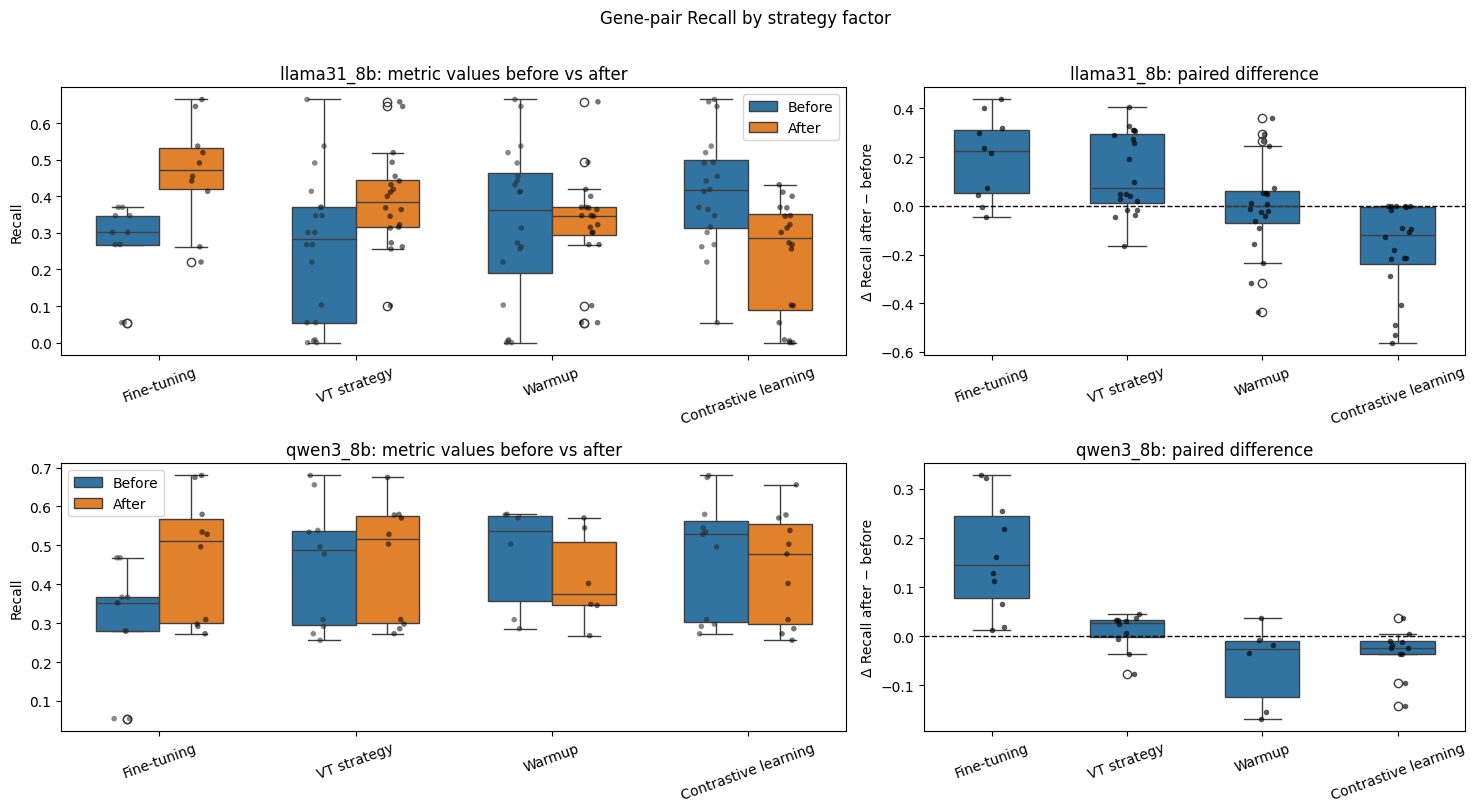

In [34]:
from pathlib import Path
import json

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# =========================
# Configuration
# =========================

MODEL_FAMILIES = [
    "llama31_8b",
    "qwen3_8b",
]

BASE_DIR = Path("../evaluation")

APPLY_ADJ = False
METRICS_FILE = "metrics_adj.json" if APPLY_ADJ else "metrics.json"

DATASETS = ["hered", "varchat", "variantscape", "bronco", "tmvar"]

# Choose the metric to analyze
TASK = "gene_variant_pair_extraction_micro"
SCORE = "recall"

TASK_LABELS = {
    "binary_detection": "Binary",
    "variant_extraction_micro": "Variant",
    "gene_variant_pair_extraction_micro": "Gene-pair",
}

SCORE_LABELS = {
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
}

DATASET_LABELS = {
    "hered": "Hered",
    "varchat": "Varchat",
    "variantscape": "VariantScape",
    "bronco": "BRONCO",
    "tmvar": "TmVar",
}

STRATEGY_ORDER = [
    "Fine-tuning",
    "VT strategy",
    "Warmup",
    "Contrastive learning",
]

LEVEL_ORDER = [
    "Before",
    "After",
]


# =========================
# Helpers
# =========================

def parse_model_name(model_name):
    """
    Parses strategy setup from names such as:

        zero_shot

        baseline
        baseline_after_warm
        baseline_contrastive
        baseline_after_warm_contrastive

        vt
        vt_after_warm
        vt_contrastive
        vt_after_warm_contrastive

    Interpretation:
        - zero_shot means non-finetuned
        - all other recognized models are fine-tuned
    """

    if model_name == "zero_shot":
        return {
            "model": model_name,
            "training_regime": "zero-shot",
            "base_strategy": "zero_shot",
            "warmup": False,
            "contrastive": False,
        }

    if model_name.startswith("baseline"):
        base_strategy = "baseline"
    elif model_name.startswith("vt"):
        base_strategy = "vt"
    else:
        return None

    warmup = "after_warm" in model_name
    contrastive = model_name.endswith("contrastive")

    return {
        "model": model_name,
        "training_regime": "fine-tuned",
        "base_strategy": base_strategy,
        "warmup": warmup,
        "contrastive": contrastive,
    }


def add_pair(
    paired_rows,
    deltas,
    model_family,
    dataset,
    strategy_factor,
    before_row,
    after_row,
    comparison,
):
    """
    Adds both raw before/after scores and paired after-before delta.
    """

    dataset_label = DATASET_LABELS.get(dataset, dataset)

    before_score = before_row["score"].iloc[0]
    after_score = after_row["score"].iloc[0]
    delta = after_score - before_score

    paired_rows.append(
        {
            "model_family": model_family,
            "dataset": dataset,
            "dataset_label": dataset_label,
            "strategy_factor": strategy_factor,
            "factor_level": "Before",
            "score": before_score,
            "comparison": comparison,
        }
    )

    paired_rows.append(
        {
            "model_family": model_family,
            "dataset": dataset,
            "dataset_label": dataset_label,
            "strategy_factor": strategy_factor,
            "factor_level": "After",
            "score": after_score,
            "comparison": comparison,
        }
    )

    deltas.append(
        {
            "model_family": model_family,
            "dataset": dataset,
            "dataset_label": dataset_label,
            "strategy_factor": strategy_factor,
            "delta": delta,
            "comparison": comparison,
        }
    )


def load_runs(model_family):
    """
    Loads all available runs for one model family.
    """

    rows = []

    for dataset in DATASETS:
        pattern = f"{model_family}_*_{dataset}"

        for run_dir in BASE_DIR.glob(pattern):
            if not run_dir.is_dir():
                continue

            metrics_path = run_dir / METRICS_FILE
            if not metrics_path.exists():
                continue

            prefix = f"{model_family}_"
            suffix = f"_{dataset}"

            run_name = run_dir.name

            if not run_name.startswith(prefix) or not run_name.endswith(suffix):
                continue

            model_name = run_name[len(prefix):-len(suffix)]

            parsed = parse_model_name(model_name)
            if parsed is None:
                continue

            with open(metrics_path) as f:
                metrics = json.load(f)

            rows.append(
                {
                    "model_family": model_family,
                    "dataset": dataset,
                    "dataset_label": DATASET_LABELS.get(dataset, dataset),
                    "score": metrics[TASK][SCORE],
                    **parsed,
                }
            )

    return pd.DataFrame(rows)


def build_pairs_for_model(model_family, df):
    """
    Builds before/after pairs and paired differences for one model family.

    Fine-tuning is restricted to:
        baseline vs zero_shot
        vt vs zero_shot

    It excludes:
        baseline_after_warm
        vt_after_warm
        baseline_contrastive
        vt_contrastive
        baseline_after_warm_contrastive
        vt_after_warm_contrastive
    """

    paired_rows = []
    deltas = []

    # -------------------------
    # 1. Fine-tuning
    # -------------------------
    # Before: zero_shot
    # After: baseline or vt only, without warmup or contrastive.
    # -------------------------

    for dataset in DATASETS:
        subset = df[df["dataset"] == dataset]

        before = subset[subset["model"] == "zero_shot"]

        after_candidates = subset[
            (subset["training_regime"] == "fine-tuned")
            & (subset["base_strategy"].isin(["baseline", "vt"]))
            & (subset["warmup"] == False)
            & (subset["contrastive"] == False)
        ]

        if len(before) == 1:
            for _, after_candidate in after_candidates.iterrows():
                after = after_candidates[
                    after_candidates["model"] == after_candidate["model"]
                ]

                comparison = f"{after_candidate['model']} vs zero_shot"

                add_pair(
                    paired_rows=paired_rows,
                    deltas=deltas,
                    model_family=model_family,
                    dataset=dataset,
                    strategy_factor="Fine-tuning",
                    before_row=before,
                    after_row=after,
                    comparison=comparison,
                )

    # -------------------------
    # 2. VT instead of baseline
    # -------------------------
    # Before: baseline
    # After: vt
    # Matched by dataset, warmup, and contrastive.
    # -------------------------

    for dataset in DATASETS:
        subset = df[df["dataset"] == dataset]

        for warmup in [False, True]:
            for contrastive in [False, True]:
                before = subset[
                    (subset["base_strategy"] == "baseline")
                    & (subset["warmup"] == warmup)
                    & (subset["contrastive"] == contrastive)
                ]

                after = subset[
                    (subset["base_strategy"] == "vt")
                    & (subset["warmup"] == warmup)
                    & (subset["contrastive"] == contrastive)
                ]

                if len(before) == 1 and len(after) == 1:
                    comparison = (
                        f"vt"
                        f"{'_after_warm' if warmup else ''}"
                        f"{'_contrastive' if contrastive else ''}"
                        " vs "
                        f"baseline"
                        f"{'_after_warm' if warmup else ''}"
                        f"{'_contrastive' if contrastive else ''}"
                    )

                    add_pair(
                        paired_rows=paired_rows,
                        deltas=deltas,
                        model_family=model_family,
                        dataset=dataset,
                        strategy_factor="VT strategy",
                        before_row=before,
                        after_row=after,
                        comparison=comparison,
                    )

    # -------------------------
    # 3. Warmup
    # -------------------------
    # Before: no warmup
    # After: after_warm
    # Matched by dataset, base strategy, and contrastive.
    # -------------------------

    for dataset in DATASETS:
        subset = df[df["dataset"] == dataset]

        for base_strategy in ["baseline", "vt"]:
            for contrastive in [False, True]:
                before = subset[
                    (subset["base_strategy"] == base_strategy)
                    & (subset["warmup"] == False)
                    & (subset["contrastive"] == contrastive)
                ]

                after = subset[
                    (subset["base_strategy"] == base_strategy)
                    & (subset["warmup"] == True)
                    & (subset["contrastive"] == contrastive)
                ]

                if len(before) == 1 and len(after) == 1:
                    comparison = (
                        f"{base_strategy}_after_warm"
                        f"{'_contrastive' if contrastive else ''}"
                        " vs "
                        f"{base_strategy}"
                        f"{'_contrastive' if contrastive else ''}"
                    )

                    add_pair(
                        paired_rows=paired_rows,
                        deltas=deltas,
                        model_family=model_family,
                        dataset=dataset,
                        strategy_factor="Warmup",
                        before_row=before,
                        after_row=after,
                        comparison=comparison,
                    )

    # -------------------------
    # 4. Contrastive
    # -------------------------
    # Before: no contrastive
    # After: contrastive
    # Matched by dataset, base strategy, and warmup.
    # -------------------------

    for dataset in DATASETS:
        subset = df[df["dataset"] == dataset]

        for base_strategy in ["baseline", "vt"]:
            for warmup in [False, True]:
                before = subset[
                    (subset["base_strategy"] == base_strategy)
                    & (subset["warmup"] == warmup)
                    & (subset["contrastive"] == False)
                ]

                after = subset[
                    (subset["base_strategy"] == base_strategy)
                    & (subset["warmup"] == warmup)
                    & (subset["contrastive"] == True)
                ]

                if len(before) == 1 and len(after) == 1:
                    comparison = (
                        f"{base_strategy}"
                        f"{'_after_warm' if warmup else ''}"
                        "_contrastive"
                        " vs "
                        f"{base_strategy}"
                        f"{'_after_warm' if warmup else ''}"
                    )

                    add_pair(
                        paired_rows=paired_rows,
                        deltas=deltas,
                        model_family=model_family,
                        dataset=dataset,
                        strategy_factor="Contrastive learning",
                        before_row=before,
                        after_row=after,
                        comparison=comparison,
                    )

    paired_df = pd.DataFrame(paired_rows)
    delta_df = pd.DataFrame(deltas)

    return paired_df, delta_df


# =========================
# Load and pair all model families
# =========================

all_loaded = []
all_paired = []
all_deltas = []

for model_family in MODEL_FAMILIES:
    model_df = load_runs(model_family)

    if model_df.empty:
        print(f"WARNING: no matching runs found for {model_family}.")
        continue

    print(f"Loaded runs for {model_family}:")
    display(
        model_df.sort_values(
            [
                "dataset",
                "training_regime",
                "base_strategy",
                "warmup",
                "contrastive",
            ]
        )
    )

    paired_df, delta_df = build_pairs_for_model(model_family, model_df)

    if paired_df.empty or delta_df.empty:
        print(f"WARNING: no valid paired comparisons found for {model_family}.")
        continue

    all_loaded.append(model_df)
    all_paired.append(paired_df)
    all_deltas.append(delta_df)

if not all_paired or not all_deltas:
    raise ValueError(
        "No valid paired comparisons found for any model family. "
        "Check BASE_DIR, MODEL_FAMILIES, DATASETS, and available run folders."
    )

loaded_df = pd.concat(all_loaded, ignore_index=True)
paired_df = pd.concat(all_paired, ignore_index=True)
delta_df = pd.concat(all_deltas, ignore_index=True)


# =========================
# Plot: one row per model family
# =========================

available_model_families = [
    model_family
    for model_family in MODEL_FAMILIES
    if model_family in paired_df["model_family"].unique()
]

n_rows = len(available_model_families)

fig, axes = plt.subplots(
    n_rows,
    2,
    figsize=(15, 4 * n_rows),
    gridspec_kw={"width_ratios": [1.45, 1]},
    squeeze=False,
)

for row_idx, model_family in enumerate(available_model_families):
    model_paired_df = paired_df[paired_df["model_family"] == model_family]
    model_delta_df = delta_df[delta_df["model_family"] == model_family]

    # -------------------------
    # Left plot: raw scores before vs after
    # -------------------------

    ax = axes[row_idx, 0]

    sns.boxplot(
        data=model_paired_df,
        x="strategy_factor",
        y="score",
        hue="factor_level",
        order=STRATEGY_ORDER,
        hue_order=LEVEL_ORDER,
        width=0.65,
        ax=ax,
    )

    sns.stripplot(
        data=model_paired_df,
        x="strategy_factor",
        y="score",
        hue="factor_level",
        order=STRATEGY_ORDER,
        hue_order=LEVEL_ORDER,
        dodge=True,
        color="black",
        size=4,
        alpha=0.55,
        ax=ax,
    )

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles[:2],
        labels[:2],
        title="",
        loc="best",
    )

    ax.set_title(f"{model_family}: metric values before vs after")
    ax.set_xlabel("")
    ax.set_ylabel(SCORE_LABELS[SCORE])
    ax.tick_params(axis="x", rotation=20)

    # -------------------------
    # Right plot: paired differences
    # -------------------------

    ax = axes[row_idx, 1]

    sns.boxplot(
        data=model_delta_df,
        x="strategy_factor",
        y="delta",
        order=STRATEGY_ORDER,
        width=0.55,
        ax=ax,
    )

    sns.stripplot(
        data=model_delta_df,
        x="strategy_factor",
        y="delta",
        order=STRATEGY_ORDER,
        color="black",
        size=4,
        alpha=0.65,
        jitter=True,
        ax=ax,
    )

    ax.axhline(0, color="black", linewidth=1, linestyle="--")

    ax.set_title(f"{model_family}: paired difference")
    ax.set_xlabel("")
    ax.set_ylabel(f"Δ {SCORE_LABELS[SCORE]} after − before")
    ax.tick_params(axis="x", rotation=20)


fig.suptitle(
    f"{TASK_LABELS[TASK]} {SCORE_LABELS[SCORE]} by strategy factor",
    y=1.01,
)

plt.tight_layout()
plt.show()